# Roubos no Rio de Janeiro: uma mudança igual para todos?

**Marco 3 — Análise Exploratória de Dados e Visualização, FGV EMAp, 2026.2**  
**Autores:** Pedro Tolentino Pires Braga e Felipe Rodolfo Pianetti  
**Docente:** Prof. João Rulff  
**Repositório:** [https://github.com/mateusdcc/roubos-rj-aed](https://github.com/mateusdcc/roubos-rj-aed) *(Mateus Cavalcanti fez parte do grupo nos Marcos 1 e 2 e criou o repositório na conta dele. Ele saiu da disciplina no começo do Marco 3.)*  
**Período:** Janeiro de 2014 a dezembro de 2024 (132 meses)

---

## Resumo

Usamos os dados mensais do ISP-RJ de 2014 a 2024 para ver se a queda dos roubos no estado aconteceu do mesmo jeito em todos os municípios. Olhamos dois crimes: roubo de rua, medido por 100 mil habitantes, e roubo de veículo, por 100 mil veículos. Trabalhamos com 82 dos 92 municípios, porque dez deles aparecem com zero em todos os crimes até abril de 2017.

A média dos municípios caiu 56,0% em roubo de rua (13,99 → 6,15) e 57,7% em roubo de veículo (20,78 → 8,80) entre 2014 e 2024. Comparando os triênios 2014–2016 e 2022–2024, as quedas foram de 56,5% (15,53 → 6,75) e 59,7% (20,47 → 8,24). Só que a queda variou bastante de lugar para lugar. Em roubo de veículo, Grande Niterói caiu 76,5% e a Baixada, 45,7%, enquanto a Capital fechou 2024 3,1% acima de 2014 por causa de uma alta de 37,1% só em 2024 (nos triênios, caiu 22,1%). Belford Roxo teve a maior alta no triênio veicular (+5,41), seguido por Rio Claro (+3,49); outros nove municípios subiram menos de 1 ponto. A distância em pontos entre os municípios diminuiu, mas a desigualdade relativa aumentou: o CV de veículos foi de 1,61 para 2,27 (+41,1%), o CV metropolitano foi de 0,63 para 0,91 (+44,3%) e o Gini subiu de 0,70 para 0,81.

Dentro do roubo de rua, o roubo de celular passou de 8,1% dos casos em 2014 para 22,2% em 2019 e 36,6% em 2024. Roubo de veículo tem um ciclo anual claro nas duas regiões, com maior índice médio em janeiro (123,9 no painel e 118,2 na região metropolitana) e menores valores no inverno (80,1 em setembro no painel; 88,6 em julho na região metropolitana). Roubo de rua não mostra sazonalidade estatisticamente significativa na região metropolitana (p = 0,4386), e o pico de fevereiro que aparece no painel (115,5) vem do Interior (119,7), onde o teste só passa sem correção (p = 0,0337) e deixa de passar sem 2020 (p = 0,0603). A resposta à pergunta do título, então, é não.

## 1. Problema e hipóteses

Entre 2014 e 2024 os roubos caíram bastante no estado do Rio. Uma média estadual, porém, pode esconder muita coisa: a queda pode ter vindo de poucos lugares, enquanto outros ficaram parados ou pioraram. Queremos saber se a redução foi parecida entre municípios e regiões ou se ficou concentrada em alguns deles. Partimos de três hipóteses:

- **H1.** A taxa média dos municípios em 2024 é menor que a de 2014, em roubo de rua e em roubo de veículo.
- **H2.** A queda não foi igual entre regiões e municípios. Medimos isso pela variação de cada região e município e pela dispersão entre eles (faixa P90−P10, coeficiente de variação e índice de Gini).
- **H3.** Os dois tipos de roubo têm um padrão mensal que se repete ao longo dos anos e aparece nas diferentes regiões.

In [1]:
from pathlib import Path
import hashlib
import json
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.ticker as mticker
from matplotlib.patches import Polygon
from matplotlib.collections import PatchCollection
import seaborn as sns
import plotly
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import scipy
from scipy import stats
from IPython.display import display, Markdown

is_nix = str(Path(sys.executable).resolve()).startswith('/nix/store/')
if is_nix:
    print('Ambiente Nix ativo, conforme flake.nix.')
else:
    print(f'Executando no Python do sistema: {sys.executable}')

versoes_df = pd.DataFrame({
    'Biblioteca': ['Python', 'pandas', 'numpy', 'scipy', 'matplotlib', 'seaborn', 'plotly'],
    'Versão': [sys.version.split()[0], pd.__version__, np.__version__, scipy.__version__,
               matplotlib.__version__, sns.__version__, plotly.__version__]
})
display(versoes_df)

ROOT = Path.cwd()
if not (ROOT / 'data/fontes.json').exists():
    raise FileNotFoundError('Execute o Jupyter na raiz do repositório, conforme o README.')
FIG = ROOT / 'figuras'
FIG.mkdir(exist_ok=True)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 180)
sns.set_theme(style='whitegrid', context='notebook', font='DejaVu Sans')
plt.rcParams.update({'figure.dpi': 120, 'savefig.dpi': 160, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.titleweight': 'bold'})

LABEL = {'roubo_rua': 'Roubo de rua', 'roubo_veiculo': 'Roubo de veículo'}
UNIT = {'roubo_rua': 'por 100 mil habitantes', 'roubo_veiculo': 'por 100 mil veículos'}
METRICS = list(LABEL)
REGIONS = ['Capital', 'Baixada Fluminense', 'Grande Niterói', 'Interior']
COLORS = dict(zip(REGIONS, ['#0072B2', '#D55E00', '#009E73', '#CC79A7']))

def _fmt_tick_dec(x, _):
    s = f"{abs(x):,.1f}".replace(',', 'X').replace('.', ',').replace('X', '.')
    return f"−{s}" if x < -1e-9 else s

def _fmt_tick_int(x, _):
    n = int(round(x))
    s = f"{abs(n):,}".replace(',', '.')
    return f"−{s}" if n < 0 else s

br_axis_fmt = mticker.FuncFormatter(_fmt_tick_dec)
br_int_axis = mticker.FuncFormatter(_fmt_tick_int)

def save(fig, name, **kwargs):
    fig.savefig(FIG / name, bbox_inches='tight', **kwargs)
    plt.show()
    plt.close(fig)

def add_source(fig, text='Fonte: ISP-RJ (2014–2024). Painel de 82 municípios; elaboração própria.'):
    fig.text(0.01, -0.02, text, fontsize=8, color='#555555')

def interpretation(text, prefix='**O que o gráfico mostra.** '):
    display(Markdown(prefix + text))

def fmt_br(val, dec=2):
    s = f"{abs(val):,.{dec}f}".replace(',', 'X').replace('.', ',').replace('X', '.')
    return f'−{s}' if val < -1e-12 else s

def fmt_sinal(val, dec=2):
    s = fmt_br(abs(val), dec)
    if val > 1e-12:
        return f'+{s}'
    return f'−{s}' if val < -1e-12 else s

def fmt_int(val):
    return f"{int(round(val)):,}".replace(',', '.')

Executando no Python do sistema: C:\Users\Pedro\AppData\Local\Programs\Python\Python312\python.exe


,Biblioteca,Versão
0,Python,3.12.10
1,pandas,3.1.1
2,numpy,2.5.1
3,scipy,1.18.0
4,matplotlib,3.11.2
5,seaborn,0.13.2
6,plotly,7.1.0


## 2. Dados, unidades e abstração

A fonte é o **Instituto de Segurança Pública do Rio de Janeiro (ISP-RJ)**, com estatísticas montadas a partir dos Registros de Ocorrência (RO) da Polícia Civil. Conforme a [nota metodológica do ISP](https://www.ispdados.rj.gov.br/metodDivulDados.html), mês e ano indicam a **data da comunicação** da ocorrência, que pode diferir da data do fato.

| Arquivo local | Papel na análise | Acesso |
|---|---|---|
| `data/taxas_municipais.csv` | Base principal de taxas mensais (`BaseMunicipioTaxaMes.csv`): 12.144 linhas, 92 municípios e 132 meses | 30/09/2026 |
| `data/contagens_municipais.csv` | Contagens mensais brutas (`BaseMunicipioMensal.csv`), usadas na decomposição de rua e na soma estadual | 07/10/2026 |
| `data/dicionario_taxas.xlsx` | Dicionário oficial das variáveis e unidades divulgado pelo ISP | 07/10/2026 |
| `data/geojs-33-mun.json` | Malha municipal GeoJSON do RJ obtida em `tbrugz/geodata-br` para o mapa da seção 6 | 18/11/2026 |

Os arquivos de taxas e contagens têm datas de acesso diferentes e podem refletir revisões distintas do ISP. Por isso, não recalculamos taxas cruzando os arquivos; a única exceção é uma aproximação da parcela populacional na seção 3, usando a razão de `registro_ocorrencias` em 2024 para checar a cobertura do painel.

### Abstração dos dados

| Atributo | Tipo | O que é |
|---|---|---|
| `fmun_cod`, `fmun` | Nominal | Código IBGE e nome do município |
| `regiao` | Nominal (4 categorias) | Capital, Baixada Fluminense, Grande Niterói ou Interior (classificação do ISP) |
| `ano`, `mes` | Temporal (ordinal) | Mês e ano de referência |
| `roubo_rua`, `roubo_celular`, `roubo_transeunte`, `roubo_em_coletivo` | Quantitativo de razão | Taxa mensal por 100 mil habitantes, calculada pelo ISP (contagens no outro arquivo) |
| `roubo_veiculo` | Quantitativo de razão | Taxa mensal por 100 mil veículos, calculada pelo ISP |
| `registro_ocorrencias` | Quantitativo de razão | Total de registros de ocorrência por 100 mil habitantes, calculado pelo ISP (usado para achar os dez municípios zerados) |
| `fase` | Categórico | 2 = consolidado sem errata; 3 = consolidado com errata |

Como os denominadores são diferentes (habitantes vs. veículos), não comparamos o nível bruto de roubo de rua com o de veículo, só as variações relativas e as trajetórias.

In [2]:
sources = json.loads((ROOT / 'data/fontes.json').read_text())
for filename, info in sources.items():
    actual = hashlib.sha256((ROOT / 'data' / filename).read_bytes()).hexdigest()
    assert actual == info['sha256'], f'O arquivo {filename} difere da cópia documentada.'

raw = pd.read_csv(ROOT / 'data/taxas_municipais.csv', sep=';', encoding='latin1', decimal=',')
counts_full = pd.read_csv(ROOT / 'data/contagens_municipais.csv', sep=';', encoding='latin1', decimal=',')
counts = counts_full[counts_full.ano.between(2014, 2024)].copy()
df = raw.copy()
KEY = ['fmun_cod', 'ano', 'mes']
required = METRICS + ['roubo_celular', 'roubo_transeunte', 'roubo_em_coletivo', 'registro_ocorrencias']
assert len(df) == 92 * 11 * 12
assert not df.duplicated(KEY).any() and not counts.duplicated(KEY).any()
assert df[required].notna().all().all()
assert (df[required] >= 0).all().all()
assert df.groupby('fmun_cod').size().eq(132).all()
assert counts.groupby('fmun_cod').size().eq(132).all()
assert set(map(tuple, df[KEY].to_numpy())) == set(map(tuple, counts[KEY].to_numpy()))
assert (counts.roubo_rua == counts.roubo_transeunte + counts.roubo_celular + counts.roubo_em_coletivo).all()
component_error = (df.roubo_rua - df.roubo_transeunte - df.roubo_celular - df.roubo_em_coletivo).abs().max()
assert component_error <= 0.021

fase2_rows = df[df.fase == 2]
print('Meses na fase 2 (sem errata):', sorted(fase2_rows[['ano', 'mes']].drop_duplicates().itertuples(index=False, name=None)))

audit = pd.DataFrame({
    'Verificação': [
        'Linhas da base de taxas', 'Municípios', 'Meses por município',
        'Chaves duplicadas', 'Ausentes nas variáveis analisadas',
        'Regiões ausentes (Paraty)', 'Meses com todos os registros de ocorrência zerados',
        'Linhas na fase 2 (out–dez de 2024)'
    ],
    'Resultado': [
        len(df), df.fmun_cod.nunique(), 132, int(df.duplicated(KEY).sum()),
        int(df[required].isna().sum().sum()), int(df.regiao.isna().sum()),
        int(df.registro_ocorrencias.eq(0).sum()), int(len(fase2_rows))
    ]
})
display(audit)
display(df[['fmun', 'ano', 'mes', 'regiao'] + METRICS + ['roubo_celular', 'fase']].head())

Meses na fase 2 (sem errata): [(2024, 10), (2024, 11), (2024, 12)]


,Verificação,Resultado
0,Linhas da base de taxas,12144
1,Municípios,92
2,Meses por município,132
3,Chaves duplicadas,0
4,Ausentes nas variáveis analisadas,0
5,Regiões ausentes (Paraty),3
6,Meses com todos os registros de ocorrência zer...,400
7,Linhas na fase 2 (out–dez de 2024),276


,fmun,ano,mes,regiao,roubo_rua,roubo_veiculo,roubo_celular,fase
0,Angra dos Reis,2014,1,Interior,3.82,15.84,0.55,3
1,Aperibé,2014,1,Interior,0.00,0.00,0.00,3
2,Araruama,2014,1,Interior,5.84,17.51,0.83,3
3,Areal,2014,1,Interior,0.00,0.00,0.00,3
4,Armação dos Búzios,2014,1,Interior,19.92,13.64,3.32,3


## 3. Limpeza, cobertura e método

O CSV do ISP usa ponto e vírgula como separador, vírgula decimal e codificação Latin-1. Três linhas de Paraty (julho, agosto e setembro de 2024) vieram sem a região; preenchemos com a região que aparece nos outros 129 meses do mesmo município (`Interior`), depois de confirmar que cada código municipal tem uma única região conhecida no arquivo.

Dez municípios (Aperibé, Areal, Carapebus, Comendador Levy Gasparian, Italva, Macuco, Paty do Alferes, Quatis, São José de Ubá e Varre-Sai) aparecem com zero em todos os crimes de janeiro de 2014 a abril de 2017, inclusive no total de registros de ocorrência. Os dados não dizem o motivo. Se mantivéssemos esses municípios, a entrada deles em maio de 2017 ia parecer um aumento de crime, então usamos um **painel balanceado de 82 municípios** (89,1% dos 92 municípios do estado). Abaixo estimamos a parcela aproximada da população estadual coberta por esse painel em 2024, e na seção 10 refazemos as contas com todos os 92 municípios para 2018–2024.

Cada taxa anual é a média das 12 taxas mensais do município, e as médias de região e do painel dão o mesmo peso a cada município. Assim, os resultados descrevem o município típico: a Capital conta como 1 em 82. Na seção 9 comparamos esse critério com as contagens somadas do estado, que dão mais peso a quem tem mais moradores.

In [3]:
known = df.dropna(subset=['regiao']).groupby('fmun_cod').regiao
assert known.nunique().eq(1).all()
df['regiao'] = df.regiao.fillna(df.fmun_cod.map(known.first()))
df['data'] = pd.to_datetime(dict(year=df.ano, month=df.mes, day=1))

coverage = df[df.registro_ocorrencias.eq(0)].groupby(['fmun_cod', 'fmun']).agg(
    meses=('mes', 'size'), inicio=('data', 'min'), fim=('data', 'max')).reset_index()
excluded = coverage.fmun_cod.tolist()
analysis = df[~df.fmun_cod.isin(excluded)].copy()
panel_counts = counts[~counts.fmun_cod.isin(excluded)].copy()
assert analysis.fmun_cod.nunique() == 82 and len(analysis) == 82 * 132
assert analysis.regiao.notna().all()
annual = analysis.groupby(['fmun_cod', 'fmun', 'regiao', 'ano'])[METRICS].mean().reset_index()
assert len(annual) == 82 * 11

# Parcela aproximada da população nos 82 municípios em 2024 (razão contagem / taxa em registro_ocorrencias)
cont_pop = pd.read_csv(ROOT / 'data/contagens_municipais.csv', sep=';', encoding='latin1')
m_pop = df[['fmun_cod', 'ano', 'mes', 'registro_ocorrencias']].merge(
    cont_pop[['fmun_cod', 'ano', 'mes', 'registro_ocorrencias']],
    on=['fmun_cod', 'ano', 'mes'], suffixes=('_tx', '_n'))
m_pop = m_pop[(m_pop.ano == 2024) & (m_pop.registro_ocorrencias_tx > 0)]
pop_est = (m_pop.registro_ocorrencias_n / m_pop.registro_ocorrencias_tx * 1e5).groupby(m_pop.fmun_cod).median()
assert len(pop_est) == 92
pop_share = 100 * pop_est[~pop_est.index.isin(excluded)].sum() / pop_est.sum()
print(f'Painel de 82 municípios: {fmt_br(pop_share, 1)}% da população estimada em 2024 (calculada nos 92 municípios via registro_ocorrencias).')

display(coverage[['fmun', 'meses', 'inicio', 'fim']])
display(analysis[['fmun_cod', 'regiao']].drop_duplicates().groupby('regiao').size().rename('Municípios do painel').to_frame())

Painel de 82 municípios: 99,2% da população estimada em 2024 (calculada nos 92 municípios via registro_ocorrencias).


,fmun,meses,inicio,fim
0,Aperibé,40,2014-01-01,2017-04-01
1,Areal,40,2014-01-01,2017-04-01
2,Carapebus,40,2014-01-01,2017-04-01
3,Comendador Levy Gasparian,40,2014-01-01,2017-04-01
4,Italva,40,2014-01-01,2017-04-01
5,Macuco,40,2014-01-01,2017-04-01
6,Paty do Alferes,40,2014-01-01,2017-04-01
7,Quatis,40,2014-01-01,2017-04-01
8,São José de Ubá,40,2014-01-01,2017-04-01
9,Varre-Sai,40,2014-01-01,2017-04-01


,Municípios do painel
regiao,
Baixada Fluminense,13
Capital,1
Grande Niterói,3
Interior,65


## 4. Pergunta 1: como mudaram as taxas médias de roubos de rua e de veículos?

**Transformação:** média mensal por município e ano, seguida de média aritmética simples entre os 82 municípios do painel.  
**Visualização:** duas linhas ordenadas no tempo em painéis separados (porque cada categoria tem um denominador diferente), com linha pontilhada em 2020.

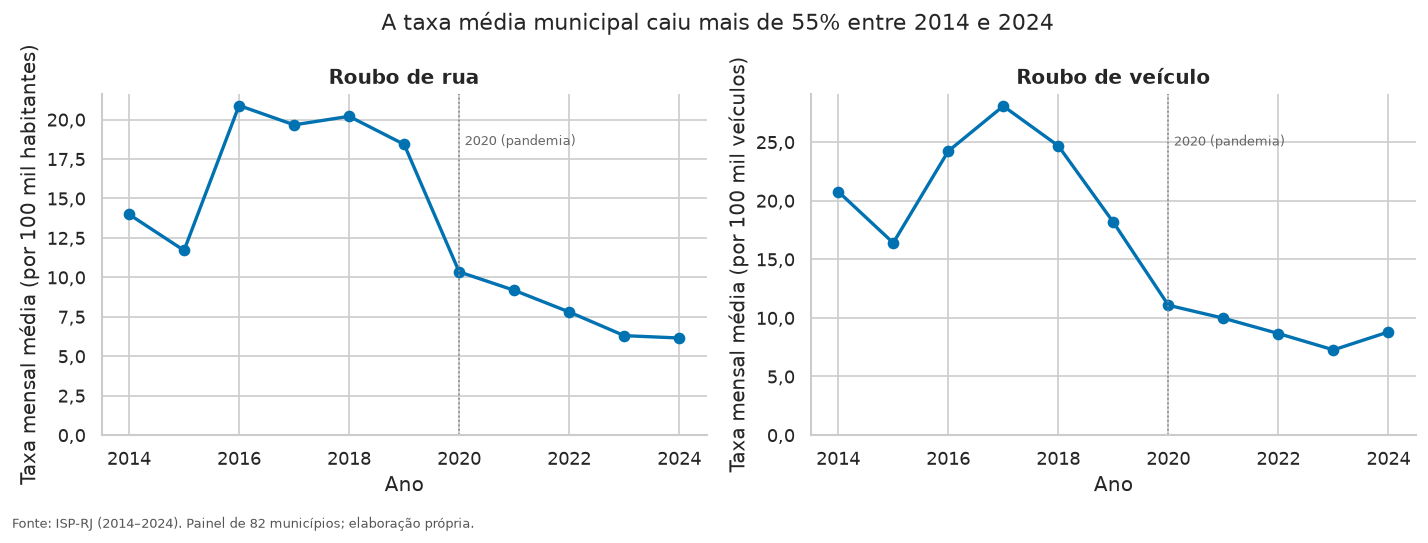

,2014–2016,2022–2024,Variação (%)
roubo_rua,15.53,6.75,-56.53
roubo_veiculo,20.47,8.24,-59.73


**O que o gráfico mostra.** Em roubo de rua, a média municipal caiu de 13,99 em 2014 para 6,15 em 2024 (−56,0%), com maior valor da série em 2016 (20,89 por 100 mil habitantes). Nos triênios 2014–2016 e 2022–2024, passou de 15,53 para 6,75 (−56,5%). Em roubo de veículo, a média municipal caiu de 20,78 em 2014 para 8,80 em 2024 (−57,7%), com maior valor da série em 2017 (28,07 por 100 mil veículos). Nos triênios 2014–2016 e 2022–2024, passou de 20,47 para 8,24 (−59,7%). Os picos de 2016 e 2017 coincidem com os anos da crise fiscal do estado; não testamos essa relação. A H1 se confirma nas duas categorias.

In [4]:
trajectory = annual.groupby('ano')[METRICS].mean()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
for ax, metric in zip(axes, METRICS):
    ax.plot(trajectory.index, trajectory[metric], marker='o', color='#0072B2', linewidth=2)
    ax.axvline(2020, color='#888888', linestyle=':', linewidth=1)
    ax.text(2020.1, trajectory[metric].max() * 0.88, '2020 (pandemia)', fontsize=8, color='#666666')
    ax.set(title=LABEL[metric], xlabel='Ano', ylabel=f'Taxa mensal média ({UNIT[metric]})', ylim=(0, None))
    ax.set_xticks([2014, 2016, 2018, 2020, 2022, 2024])
    ax.yaxis.set_major_formatter(br_axis_fmt)

fig.suptitle('A taxa média municipal caiu mais de 55% entre 2014 e 2024', fontsize=13)
add_source(fig)
fig.tight_layout()
save(fig, '01_trajetorias.png')

# Comparação por triênios no painel de 82 municípios
tri_painel_ini = annual[annual.ano.between(2014, 2016)].groupby('fmun_cod')[METRICS].mean().mean()
tri_painel_fim = annual[annual.ano.between(2022, 2024)].groupby('fmun_cod')[METRICS].mean().mean()
tri_painel_var = 100 * (tri_painel_fim / tri_painel_ini - 1)
display(pd.DataFrame({'2014–2016': tri_painel_ini, '2022–2024': tri_painel_fim, 'Variação (%)': tri_painel_var}).round(2))

changes = 100 * (trajectory.loc[2024] / trajectory.loc[2014] - 1)
lines_q1 = []
for metric in METRICS:
    peak_yr = int(trajectory[metric].idxmax())
    peak_val = trajectory.loc[peak_yr, metric]
    v14, v24 = trajectory.loc[2014, metric], trajectory.loc[2024, metric]
    t14, t24 = tri_painel_ini[metric], tri_painel_fim[metric]
    lines_q1.append(
        f'Em {LABEL[metric].lower()}, a média municipal caiu de {fmt_br(v14)} em 2014 para {fmt_br(v24)} em 2024 '
        f'({fmt_sinal(changes[metric], 1)}%), com maior valor da série em {peak_yr} ({fmt_br(peak_val)} {UNIT[metric]}). '
        f'Nos triênios 2014–2016 e 2022–2024, passou de {fmt_br(t14)} para {fmt_br(t24)} ({fmt_sinal(tri_painel_var[metric], 1)}%).'
    )
lines_q1.append('Os picos de 2016 e 2017 coincidem com os anos da crise fiscal do estado; não testamos essa relação. A H1 se confirma nas duas categorias.')
interpretation(' '.join(lines_q1))

## 5. Pergunta 2: as trajetórias foram semelhantes nas quatro regiões?

**Transformação:** média das taxas anuais dos municípios em cada macrorregião definida pelo ISP (Capital, Baixada Fluminense, Grande Niterói e Interior), com igual peso por município.  
**Visualização:** painéis lado a lado com cores e estilos de linha distintos por região, além de versão interativa (`figuras/regioes_interativo.html`) para ler valores exatos e isolar regiões.

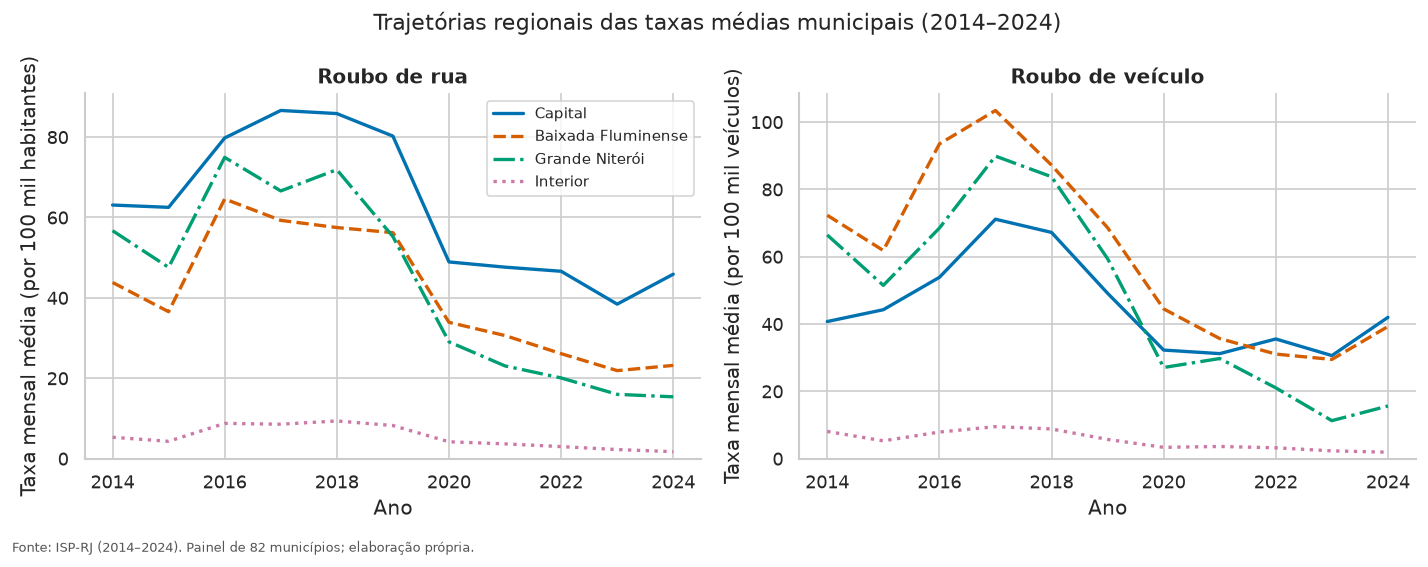

roubo_rua        roubo_veiculo       
ano                     2014   2024          2014   2024
regiao                                                  
Baixada Fluminense     43.82  23.18         72.30  39.24
Capital                63.08  45.87         40.71  41.96
Grande Niterói         56.70  15.36         66.44  15.62
Interior                5.30   1.71          8.06   1.89

2014–2016               2022–2024                  roubo_rua roubo_veiculo
                   roubo_rua roubo_veiculo roubo_rua roubo_veiculo Variação (%)  Variação (%)
regiao                                                                                       
Baixada Fluminense     48.32         75.87     23.72         33.25       -50.91        -56.18
Capital                68.45         46.26     43.63         36.03       -36.26        -22.12
Grande Niterói         59.74         62.13     17.13         15.96       -71.32        -74.30
Interior                6.11          7.07      2.31          2.46       -62.23        -65.24

**O que o gráfico mostra.** Em roubo de veículo, a Capital terminou 2024 com taxa 3,1% maior que a de 2014 (40,71 → 41,96). Olhando a série inteira, ela subiu até 71,12 em 2017, caiu até 30,60 em 2023 e voltou a subir 37,1% em 2024. Nos triênios (2014–2016 vs. 2022–2024), a Capital também caiu, de 46,26 para 36,03 (−22,1%). A alta no ponto a ponto vem, portanto, de um ano só.

A Baixada Fluminense caiu de 72,30 para 39,24 (−45,7%; −56,2% nos triênios), Grande Niterói de 66,44 para 15,62 (−76,5%; −74,3% nos triênios) e o Interior de 8,06 para 1,89 (−76,6%; −65,2% nos triênios). Em roubo de rua, a Capital tinha em 2024 a maior taxa média (45,87), seguida de Baixada (23,18), Grande Niterói (15,36) e Interior (1,71). A Capital é um município só e Grande Niterói são três, então essas duas curvas variam bem mais que a do Interior, que tem 65.

In [5]:
regional = annual.groupby(['regiao', 'ano'])[METRICS].mean().reset_index()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
styles = ['-', '--', '-.', ':']
interactive = make_subplots(rows=1, cols=2, subplot_titles=list(LABEL.values()))
for col, (ax, metric) in enumerate(zip(axes, METRICS), 1):
    for region, style in zip(REGIONS, styles):
        part = regional[regional.regiao.eq(region)]
        ax.plot(part.ano, part[metric], color=COLORS[region], linestyle=style, label=region, linewidth=2)
        interactive.add_trace(go.Scatter(x=part.ano, y=part[metric], name=region,
            legendgroup=region, showlegend=col==1, mode='lines+markers',
            line=dict(color=COLORS[region], dash={'-':'solid','--':'dash','-.':'dashdot',':':'dot'}[style]),
            hovertemplate=f'{region}<br>Ano: %{{x}}<br>Taxa: %{{y:.2f}} {UNIT[metric]}<extra></extra>'), row=1, col=col)
    ax.set(title=LABEL[metric], xlabel='Ano', ylabel=f'Taxa mensal média ({UNIT[metric]})', ylim=(0, None))
    ax.yaxis.set_major_formatter(br_int_axis)
    interactive.update_yaxes(title_text=UNIT[metric], row=1, col=col)
axes[0].legend(fontsize=9)
fig.suptitle('Trajetórias regionais das taxas médias municipais (2014–2024)', fontsize=13)
add_source(fig)
fig.tight_layout()
save(fig, '02_regioes.png')
interactive.update_layout(template='plotly_white', height=460, title='Trajetórias regionais: médias municipais sem ponderação',
                          margin=dict(l=65, r=30, t=80, b=60))
interactive.write_html(FIG / 'regioes_interativo.html', include_plotlyjs=True)
interactive.show(renderer='notebook')

region_compare = regional[regional.ano.isin([2014, 2024])].pivot(index='regiao', columns='ano', values=METRICS)
display(region_compare.round(2))

def tri(a, b):
    sub = annual[annual.ano.between(a, b)]
    return sub.groupby(['regiao'])[METRICS].mean()

tri_ini, tri_fim = tri(2014, 2016), tri(2022, 2024)
tri_comp = pd.concat({'2014–2016': tri_ini, '2022–2024': tri_fim}, axis=1)
tri_comp[('roubo_rua', 'Variação (%)')] = 100 * (tri_fim['roubo_rua'] / tri_ini['roubo_rua'] - 1)
tri_comp[('roubo_veiculo', 'Variação (%)')] = 100 * (tri_fim['roubo_veiculo'] / tri_ini['roubo_veiculo'] - 1)
display(tri_comp.round(2))

# Variáveis para o texto
v_cap_veic_14 = region_compare.loc['Capital', ('roubo_veiculo', 2014)]
v_cap_veic_24 = region_compare.loc['Capital', ('roubo_veiculo', 2024)]
var_cap_veic = 100 * (v_cap_veic_24 / v_cap_veic_14 - 1)
cap_series_v = regional[regional.regiao == 'Capital'].set_index('ano')['roubo_veiculo']
cap_pico_val, cap_pico_ano = cap_series_v.max(), int(cap_series_v.idxmax())
cap_min_val = cap_series_v.loc[2023]
cap_repique = 100 * (v_cap_veic_24 / cap_min_val - 1)
cap_tri_14, cap_tri_24 = tri_ini.loc['Capital', 'roubo_veiculo'], tri_fim.loc['Capital', 'roubo_veiculo']
var_cap_tri_v = 100 * (cap_tri_24 / cap_tri_14 - 1)

v_bx_veic_14 = region_compare.loc['Baixada Fluminense', ('roubo_veiculo', 2014)]
v_bx_veic_24 = region_compare.loc['Baixada Fluminense', ('roubo_veiculo', 2024)]
var_bx_veic = 100 * (v_bx_veic_24 / v_bx_veic_14 - 1)
var_bx_tri_v = 100 * (tri_fim.loc['Baixada Fluminense', 'roubo_veiculo'] / tri_ini.loc['Baixada Fluminense', 'roubo_veiculo'] - 1)

v_gn_veic_14 = region_compare.loc['Grande Niterói', ('roubo_veiculo', 2014)]
v_gn_veic_24 = region_compare.loc['Grande Niterói', ('roubo_veiculo', 2024)]
var_gn_veic = 100 * (v_gn_veic_24 / v_gn_veic_14 - 1)
var_gn_tri_v = 100 * (tri_fim.loc['Grande Niterói', 'roubo_veiculo'] / tri_ini.loc['Grande Niterói', 'roubo_veiculo'] - 1)

v_int_veic_14 = region_compare.loc['Interior', ('roubo_veiculo', 2014)]
v_int_veic_24 = region_compare.loc['Interior', ('roubo_veiculo', 2024)]
var_int_veic = 100 * (v_int_veic_24 / v_int_veic_14 - 1)
var_int_tri_v = 100 * (tri_fim.loc['Interior', 'roubo_veiculo'] / tri_ini.loc['Interior', 'roubo_veiculo'] - 1)

v_cap_rua_24 = region_compare.loc['Capital', ('roubo_rua', 2024)]
v_bx_rua_24 = region_compare.loc['Baixada Fluminense', ('roubo_rua', 2024)]
v_gn_rua_24 = region_compare.loc['Grande Niterói', ('roubo_rua', 2024)]
v_int_rua_24 = region_compare.loc['Interior', ('roubo_rua', 2024)]

interpretation(
    f'Em roubo de veículo, a Capital terminou 2024 com taxa {fmt_br(var_cap_veic, 1)}% maior que a de 2014 '
    f'({fmt_br(v_cap_veic_14)} → {fmt_br(v_cap_veic_24)}). Olhando a série inteira, ela subiu até {fmt_br(cap_pico_val)} em {cap_pico_ano}, '
    f'caiu até {fmt_br(cap_min_val)} em 2023 e voltou a subir {fmt_br(cap_repique, 1)}% em 2024. '
    f'Nos triênios (2014–2016 vs. 2022–2024), a Capital também caiu, de {fmt_br(cap_tri_14)} para {fmt_br(cap_tri_24)} ({fmt_sinal(var_cap_tri_v, 1)}%). '
    f'A alta no ponto a ponto vem, portanto, de um ano só.\n\n'
    f'A Baixada Fluminense caiu de {fmt_br(v_bx_veic_14)} para {fmt_br(v_bx_veic_24)} ({fmt_sinal(var_bx_veic, 1)}%; {fmt_sinal(var_bx_tri_v, 1)}% nos triênios), '
    f'Grande Niterói de {fmt_br(v_gn_veic_14)} para {fmt_br(v_gn_veic_24)} ({fmt_sinal(var_gn_veic, 1)}%; {fmt_sinal(var_gn_tri_v, 1)}% nos triênios) '
    f'e o Interior de {fmt_br(v_int_veic_14)} para {fmt_br(v_int_veic_24)} ({fmt_sinal(var_int_veic, 1)}%; {fmt_sinal(var_int_tri_v, 1)}% nos triênios). '
    f'Em roubo de rua, a Capital tinha em 2024 a maior taxa média ({fmt_br(v_cap_rua_24)}), seguida de Baixada ({fmt_br(v_bx_rua_24)}), '
    f'Grande Niterói ({fmt_br(v_gn_rua_24)}) e Interior ({fmt_br(v_int_rua_24)}). '
    f'A Capital é um município só e Grande Niterói são três, então essas duas curvas variam bem mais que a do Interior, que tem 65.'
)

## 6. Pergunta 3: quais municípios tiveram as maiores alterações absolutas?

**Transformação:** diferença absoluta das taxas anuais (2024 menos 2014) por município e comparação equivalente entre os triênios 2022–2024 e 2014–2016 para suavizar oscilações de um único ano.  
**Visualização:** barras divergentes para as cinco maiores altas e cinco maiores quedas de cada categoria (porque o que importa é o sinal e o tamanho da diferença em pontos), acompanhadas de mapa coroplético com escala divergente centrada em zero, contorno escuro nos municípios que subiram e rótulo nos dois casos com alta acima de 1 ponto.

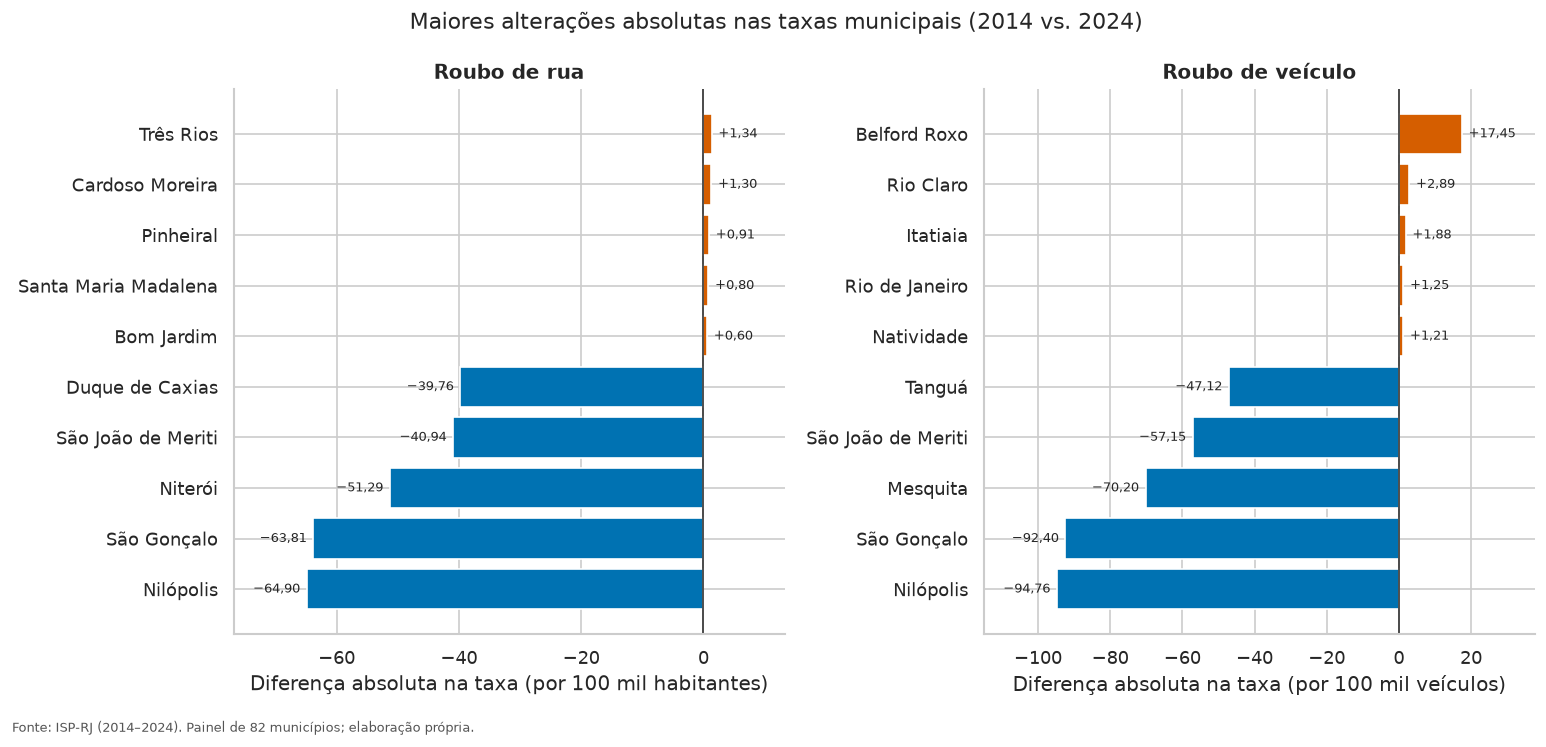

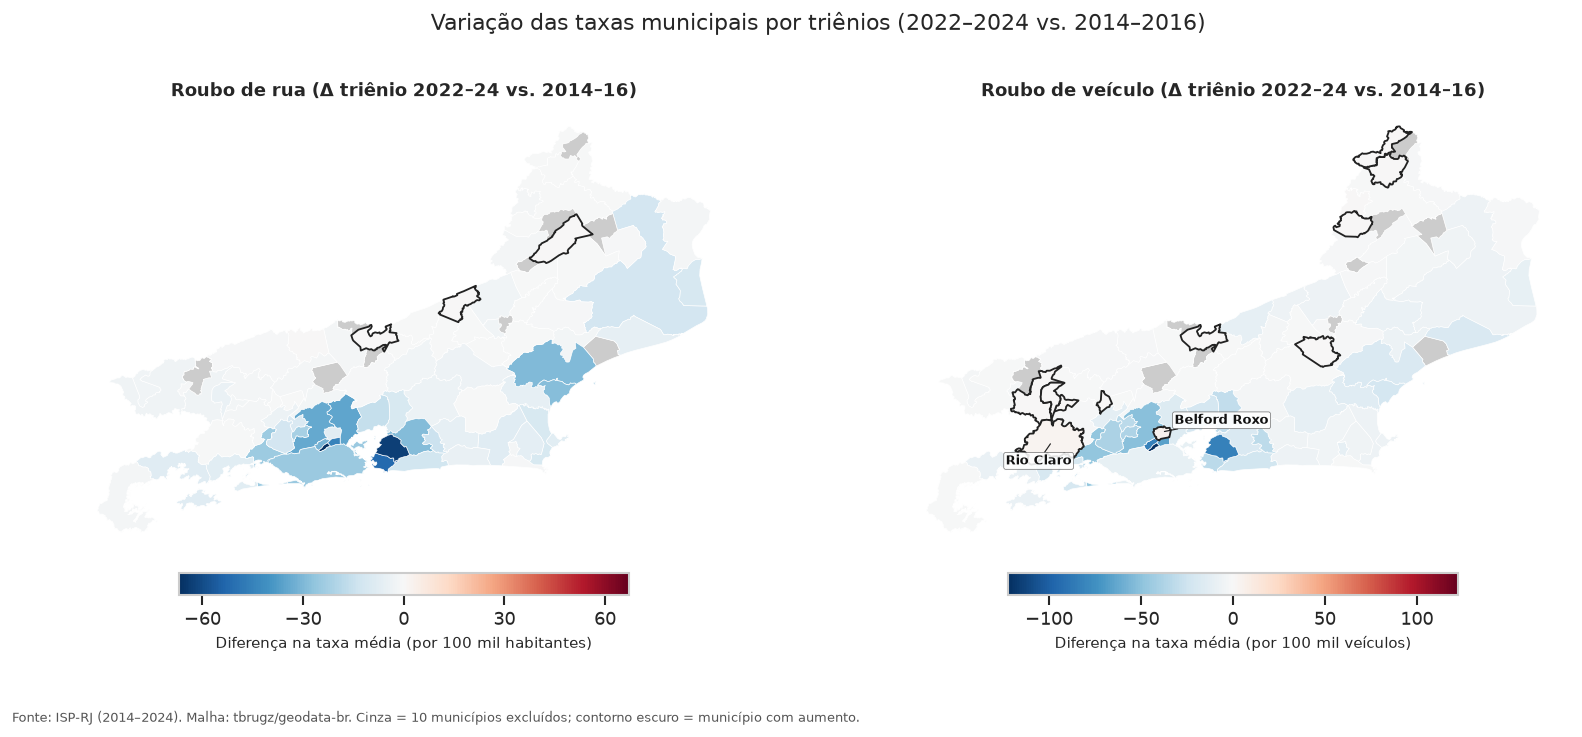

,2014–16,2022–24,Variação (%)
roubo_rua,15.53,6.75,-56.53
roubo_veiculo,20.47,8.24,-59.73


Belford Roxo, veículos (triênios): 88,68 → 94,09 (+5,41)
Municípios com aumento nos triênios — Roubo de rua (3):


,,,Δ triênio
fmun_cod,fmun,regiao,
3306008,Três Rios,Interior,0.29
3301207,Carmo,Interior,0.27
3300902,Cambuci,Interior,0.16


Municípios com aumento nos triênios — Roubo de veículo (11):


,,,Δ triênio
fmun_cod,fmun,regiao,
3300456,Belford Roxo,Baixada Fluminense,5.41
3304409,Rio Claro,Interior,3.49
3306305,Volta Redonda,Interior,0.73
3304102,Porciúncula,Interior,0.61
3303104,Natividade,Interior,0.40
3303955,Pinheiral,Interior,0.33
3302809,Mendes,Interior,0.24
3303005,Miracema,Interior,0.22
3300506,Bom Jardim,Interior,0.13


**O que o gráfico mostra.** Na comparação de 2014 contra 2024, 65 municípios caíram em roubo de rua, 12 subiram e 5 ficaram estáveis; os maiores aumentos em pontos foram Três Rios (+1,34), Cardoso Moreira (+1,30) e Pinheiral (+0,91). Em Três Rios, essa alta (+1,34 na taxa média mensal) corresponde a uma mudança de 14 para 28 ocorrências anuais nas contagens. Em roubo de veículo, 65 caíram, 7 subiram e 10 ficaram iguais (56 caíram nos dois crimes ao mesmo tempo).

Nos triênios (2022–2024 vs. 2014–2016), 78 municípios caíram em rua e 3 subiram (Três Rios +0,29, Carmo +0,27 e Cambuci +0,16). Em veículo, 70 caíram, 1 ficou estável e 11 subiram: Belford Roxo teve a maior alta (+5,41, de 88,68 para 94,09), seguido de Rio Claro (+3,49), enquanto outros 9 municípios subiram menos de 1 ponto. No ponto a ponto, Belford Roxo passou de 95,78 para 113,22 (+17,45 pontos), com maior valor da série em 2018 (206,55). Em direção oposta, outros municípios metropolitanos registraram as maiores quedas em pontos, como Nilópolis (−94,76) e São Gonçalo (−92,40). No mapa de veículos, o contorno escuro e os rótulos marcam Belford Roxo e Rio Claro, já que na escala simétrica suas cores ficam claras perto das quedas metropolitanas acima de 100 pontos.

In [6]:
comparison = annual[annual.ano.isin([2014, 2024])].pivot(
    index=['fmun_cod', 'fmun', 'regiao'], columns='ano', values=METRICS)
deltas = pd.DataFrame(index=comparison.index)
for metric in METRICS:
    deltas[metric] = comparison[metric][2024] - comparison[metric][2014]

# 1. Barras divergentes
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for ax, metric in zip(axes, METRICS):
    ordered = deltas[metric].sort_values()
    selected = pd.concat([ordered.head(5), ordered.tail(5)]).sort_values()
    bars = ax.barh(selected.index.get_level_values('fmun'), selected,
                   color=np.where(selected < 0, '#0072B2', '#D55E00'))
    ax.axvline(0, color='#333333', linewidth=1)
    ax.margins(x=0.18)
    ax.xaxis.set_major_formatter(br_int_axis)
    ax.set(title=LABEL[metric], xlabel=f'Diferença absoluta na taxa ({UNIT[metric]})')
    for bar in bars:
        w = bar.get_width()
        ha = 'left' if w > 0 else 'right'
        ax.annotate(f'{fmt_sinal(w, 2)}', (w, bar.get_y() + bar.get_height() / 2),
                    xytext=(4 if w > 0 else -4, 0), textcoords='offset points',
                    va='center', ha=ha, fontsize=8)

fig.suptitle('Maiores alterações absolutas nas taxas municipais (2014 vs. 2024)', fontsize=13)
add_source(fig)
fig.tight_layout()
save(fig, '03_mudancas_municipais.png')

# 2. Mapa por triênios
with open(ROOT / 'data/geojs-33-mun.json', encoding='utf-8') as f:
    geo = json.load(f)

def tri_mun(a, b):
    sub = annual[annual.ano.between(a, b)]
    return sub.groupby(['fmun_cod', 'fmun', 'regiao'])[METRICS].mean()

t_ini_m, t_fim_m = tri_mun(2014, 2016), tri_mun(2022, 2024)
delta_tri_m = t_fim_m - t_ini_m
var_tri = 100 * (t_fim_m.mean() / t_ini_m.mean() - 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.8))
for ax, metric, title in [(ax1, 'roubo_rua', 'Roubo de rua'), (ax2, 'roubo_veiculo', 'Roubo de veículo')]:
    dt_dict = delta_tri_m[metric].to_dict()
    vals = list(dt_dict.values())
    lim = max(abs(min(vals)), abs(max(vals)))
    norm = mcolors.TwoSlopeNorm(vcenter=0, vmin=-lim, vmax=lim)
    cmap = plt.cm.RdBu_r

    patches_base, colors_base = [], []
    patches_up, colors_up = [], []
    for feat in geo['features']:
        ibge = int(feat['properties']['id'])
        val = next((dt_dict[k] for k in dt_dict if k[0] == ibge), None)
        col = '#CCCCCC' if val is None else cmap(norm(val))
        subiu = val is not None and val > 0
        for ring in feat['geometry']['coordinates']:
            if subiu:
                patches_up.append(Polygon(ring, closed=True))
                colors_up.append(col)
            else:
                patches_base.append(Polygon(ring, closed=True))
                colors_base.append(col)
        if subiu and val > 1:
            main_ring = max(feat['geometry']['coordinates'], key=len)
            x, y = np.array(main_ring).mean(axis=0)
            lbl = feat['properties']['name']
            offset = (8, 5) if lbl == 'Belford Roxo' else (-28, -14)
            ax.annotate(lbl, (x, y), fontsize=7.5, fontweight='bold', color='#111111',
                        xytext=offset, textcoords='offset points', zorder=10,
                        bbox=dict(boxstyle='round,pad=0.15', facecolor='white', edgecolor='#555555', linewidth=0.4, alpha=0.88),
                        arrowprops=dict(arrowstyle='-', color='#222222', linewidth=0.7, shrinkA=0, shrinkB=2))

    ax.add_collection(PatchCollection(patches_base, facecolors=colors_base, edgecolors='white', linewidths=0.4, zorder=1))
    if patches_up:
        ax.add_collection(PatchCollection(patches_up, facecolors=colors_up, edgecolors='#222222', linewidths=1.1, zorder=3))
    ax.autoscale()
    ax.set_aspect('equal')
    ax.axis('off')
    ax.set_title(f'{title} (Δ triênio 2022–24 vs. 2014–16)', fontsize=11, fontweight='bold')
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    cbar = fig.colorbar(sm, ax=ax, orientation='horizontal', fraction=0.046, pad=0.04)
    cbar.ax.xaxis.set_major_locator(mticker.MaxNLocator(5, integer=True))
    cbar.ax.xaxis.set_major_formatter(br_int_axis)
    cbar.set_label(f'Diferença na taxa média ({UNIT[metric]})', fontsize=9)

fig.suptitle('Variação das taxas municipais por triênios (2022–2024 vs. 2014–2016)', fontsize=13, y=0.98)
fig.text(0.02, -0.04, 'Fonte: ISP-RJ (2014–2024). Malha: tbrugz/geodata-br. Cinza = 10 municípios excluídos; contorno escuro = município com aumento.', fontsize=8, color='#555555')
fig.tight_layout(rect=[0, 0.03, 1, 0.94])
save(fig, '10_mapa_municipal.png')

# Impressão das médias por triênio, Belford Roxo e lista completa de quem subiu nos triênios
display(pd.DataFrame({'2014–16': t_ini_m.mean(), '2022–24': t_fim_m.mean(), 'Variação (%)': var_tri}).round(2))
bel = 'Belford Roxo'
bel_t14 = t_ini_m.xs(bel, level='fmun')['roubo_veiculo'].iloc[0]
bel_t24 = t_fim_m.xs(bel, level='fmun')['roubo_veiculo'].iloc[0]
print('Belford Roxo, veículos (triênios):', fmt_br(bel_t14), '→', fmt_br(bel_t24), f'({fmt_sinal(bel_t24 - bel_t14)})')

for metric in METRICS:
    subiu_df = delta_tri_m[delta_tri_m[metric] > 0][metric].sort_values(ascending=False).round(2)
    print(f'Municípios com aumento nos triênios — {LABEL[metric]} ({len(subiu_df)}):')
    display(subiu_df.to_frame('Δ triênio'))

# Extração dinâmica dos valores para interpretação
bel_series_v = annual[annual.fmun == 'Belford Roxo'].set_index('ano')['roubo_veiculo']
bel_14, bel_24 = bel_series_v.loc[2014], bel_series_v.loc[2024]
bel_pico_val, bel_pico_ano = bel_series_v.max(), int(bel_series_v.idxmax())
belford_veic = deltas.xs('Belford Roxo', level='fmun')['roubo_veiculo'].values[0]
bel_tri_delta = delta_tri_m.xs('Belford Roxo', level='fmun')['roubo_veiculo'].values[0]

nilopolis_veic = deltas.xs('Nilópolis', level='fmun')['roubo_veiculo'].values[0]
sg_veic = deltas.xs('São Gonçalo', level='fmun')['roubo_veiculo'].values[0]

q_rua = int((deltas.roubo_rua < 0).sum())
a_rua = int((deltas.roubo_rua > 0).sum())
e_rua = int((deltas.roubo_rua == 0).sum())
q_veic = int((deltas.roubo_veiculo < 0).sum())
a_veic = int((deltas.roubo_veiculo > 0).sum())
e_veic = int((deltas.roubo_veiculo == 0).sum())
q_ambas = int(((deltas.roubo_rua < 0) & (deltas.roubo_veiculo < 0)).sum())

q_tri_rua = int((delta_tri_m.roubo_rua < 0).sum())
a_tri_rua = int((delta_tri_m.roubo_rua > 0).sum())
q_tri_veic = int((delta_tri_m.roubo_veiculo < 0).sum())
a_tri_veic = int((delta_tri_m.roubo_veiculo > 0).sum())
e_tri_veic = int((delta_tri_m.roubo_veiculo == 0).sum())

up_rua_tri = delta_tri_m[delta_tri_m.roubo_rua > 0]['roubo_rua'].sort_values(ascending=False)
up_rua_items = [f'{k[1]} {fmt_sinal(v)}' for k, v in up_rua_tri.items()]
up_rua_txt = ', '.join(up_rua_items[:-1]) + ' e ' + up_rua_items[-1] if len(up_rua_items) > 1 else ''.join(up_rua_items)
up_veic_tri = delta_tri_m[delta_tri_m.roubo_veiculo > 0]['roubo_veiculo'].sort_values(ascending=False)
rc_tri_delta = up_veic_tri.xs('Rio Claro', level='fmun').iloc[0]
n_sub_menor1 = int((up_veic_tri < 1).sum())

top3_rua = deltas['roubo_rua'].sort_values(ascending=False).head(3)
top3_nomes = top3_rua.index.get_level_values('fmun').tolist()
top3_str = f"{top3_nomes[0]} ({fmt_sinal(top3_rua.iloc[0])}), {top3_nomes[1]} ({fmt_sinal(top3_rua.iloc[1])}) e {top3_nomes[2]} ({fmt_sinal(top3_rua.iloc[2])})"
tr_oc_14 = int(panel_counts[(panel_counts.fmun == 'Três Rios') & (panel_counts.ano == 2014)]['roubo_rua'].sum())
tr_oc_24 = int(panel_counts[(panel_counts.fmun == 'Três Rios') & (panel_counts.ano == 2024)]['roubo_rua'].sum())

interpretation(
    f'Na comparação de 2014 contra 2024, {q_rua} municípios caíram em roubo de rua, {a_rua} subiram e {e_rua} ficaram estáveis; '
    f'os maiores aumentos em pontos foram {top3_str}. Em Três Rios, essa alta (+{fmt_br(top3_rua.iloc[0])} na taxa média mensal) '
    f'corresponde a uma mudança de {tr_oc_14} para {tr_oc_24} ocorrências anuais nas contagens. Em roubo de veículo, {q_veic} caíram, '
    f'{a_veic} subiram e {e_veic} ficaram iguais ({q_ambas} caíram nos dois crimes ao mesmo tempo).\n\n'
    f'Nos triênios (2022–2024 vs. 2014–2016), {q_tri_rua} municípios caíram em rua e {a_tri_rua} subiram ({up_rua_txt}). '
    f'Em veículo, {q_tri_veic} caíram, {e_tri_veic} ficou estável e {a_tri_veic} subiram: Belford Roxo teve a maior alta '
    f'({fmt_sinal(bel_tri_delta)}, de {fmt_br(bel_t14)} para {fmt_br(bel_t24)}), seguido de Rio Claro ({fmt_sinal(rc_tri_delta)}), '
    f'enquanto outros {n_sub_menor1} municípios subiram menos de 1 ponto. No ponto a ponto, Belford Roxo passou de {fmt_br(bel_14)} para {fmt_br(bel_24)} '
    f'({fmt_sinal(belford_veic)} pontos), com maior valor da série em {bel_pico_ano} ({fmt_br(bel_pico_val)}). '
    f'Em direção oposta, outros municípios metropolitanos registraram as maiores quedas em pontos, como Nilópolis ({fmt_sinal(nilopolis_veic)}) '
    f'e São Gonçalo ({fmt_sinal(sg_veic)}). No mapa de veículos, o contorno escuro e os rótulos marcam Belford Roxo e Rio Claro, já que na escala simétrica suas cores ficam claras perto das quedas metropolitanas acima de 100 pontos.'
)

## 7. Pergunta 4: a distância entre os municípios aumentou ou diminuiu?

**Transformação:** mediana, percentis 10 e 90, coeficiente de variação (desvio padrão / média), índice de Gini e participação dos 8 municípios de maior taxa na soma das taxas dos 82 municípios, ano a ano.  
**Visualização:** três painéis lado a lado — faixa P10–P90 com a mediana (a faixa mostra dispersão entre municípios, não intervalo de confiança) para cada crime e as curvas de CV juntas no terceiro painel para comparar a desigualdade relativa na mesma escala.

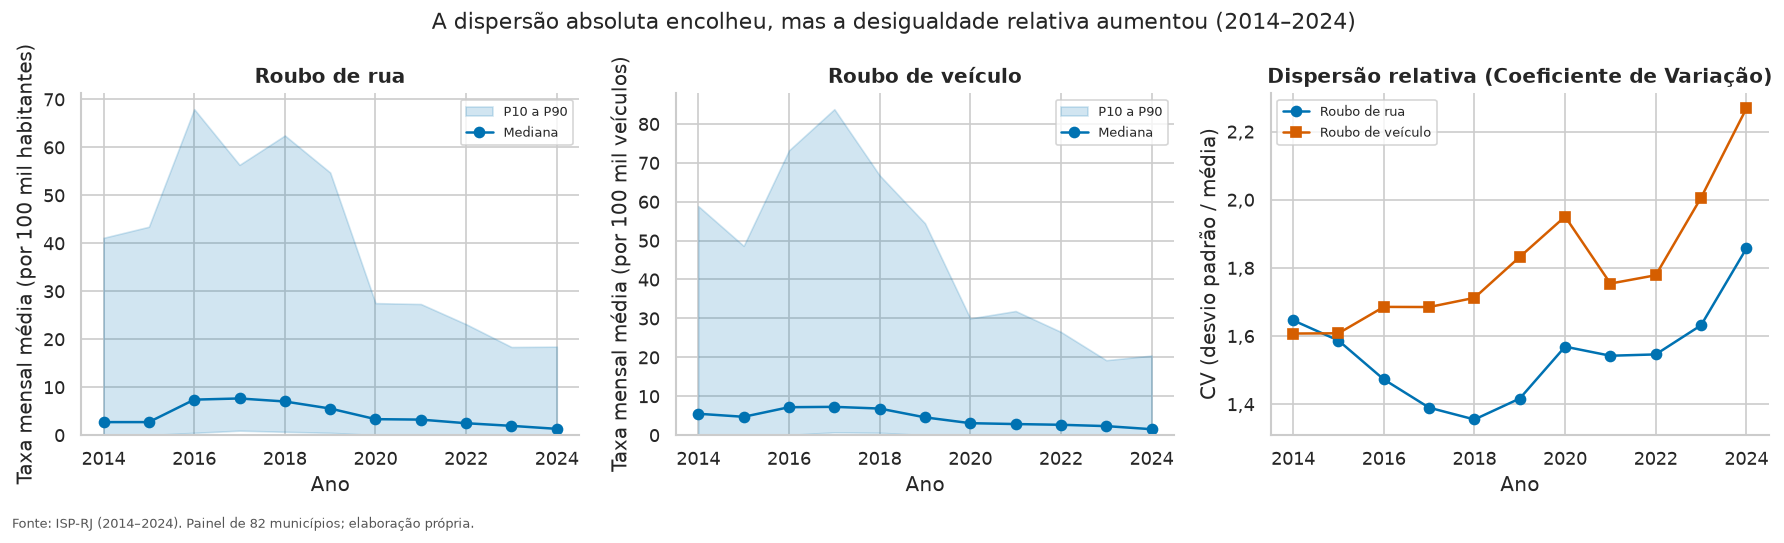

,Categoria,CV 2014,CV 2024,Var. CV,Gini 2014,Gini 2024,CV Metro 2014,CV Metro 2024,Var. CV Metro,Top 8 (soma taxas) 2014,Top 8 (soma taxas) 2024
0,Roubo de rua,"1,65","1,86","+12,8%","0,72","0,75","0,64","0,69","+7,6%","52,9%","59,9%"
1,Roubo de veículo,"1,61","2,27","+41,1%","0,70","0,81","0,63","0,91","+44,3%","51,7%","69,4%"


**O que o gráfico mostra.** A faixa interdecil (P90−P10) encolheu 55,2% em roubo de rua (41,12 → 18,43) e 65,3% em roubo de veículo (58,84 → 20,43). Como o P10 é zero em muitos anos, a faixa encolheu porque o P90 caiu.

Em termos relativos, o coeficiente de variação (CV) subiu de 1,65 para 1,86 (+12,8%) em rua e de 1,61 para 2,27 (+41,1%) em veículo. O Gini subiu de 0,72 para 0,75 em rua e de 0,70 para 0,81 em veículo. Calculamos também a participação dos 8 municípios de taxa mais alta como a soma das taxas desses 8 dividida pela soma das taxas dos 82 (não é a fatia do total de ocorrências): ela foi de 52,9% para 59,9% em rua e de 51,7% para 69,4% em veículo. Mesmo olhando só a região metropolitana do ISP, o CV de veículos subiu de 0,63 para 0,91 (+44,3%). Ou seja, a distância em pontos diminuiu, mas em termos relativos os municípios ficaram mais desiguais.

In [7]:
quantiles = annual.groupby('ano')[METRICS].quantile([.1, .5, .9]).unstack()
cv_series = annual.groupby('ano')[METRICS].agg(lambda s: s.std() / s.mean())

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 4.3))
for ax, metric in zip([ax1, ax2], METRICS):
    q = quantiles[metric]
    ax.fill_between(q.index, q[.1], q[.9], color='#0072B2', alpha=.18, label='P10 a P90')
    ax.plot(q.index, q[.5], color='#0072B2', marker='o', label='Mediana')
    ax.set(title=LABEL[metric], xlabel='Ano', ylabel=f'Taxa mensal média ({UNIT[metric]})', ylim=(0, None))
    ax.yaxis.set_major_formatter(br_int_axis)
    ax.legend(fontsize=8)

ax3.plot(cv_series.index, cv_series['roubo_rua'], marker='o', color='#0072B2', label='Roubo de rua')
ax3.plot(cv_series.index, cv_series['roubo_veiculo'], marker='s', color='#D55E00', label='Roubo de veículo')
ax3.set(title='Dispersão relativa (Coeficiente de Variação)', xlabel='Ano', ylabel='CV (desvio padrão / média)')
ax3.yaxis.set_major_formatter(br_axis_fmt)
ax3.legend(fontsize=8)

fig.suptitle('A dispersão absoluta encolheu, mas a desigualdade relativa aumentou (2014–2024)', fontsize=13)
add_source(fig)
fig.tight_layout()
save(fig, '04_dispersao.png')

def calc_gini(x):
    x = np.sort(np.asarray(x, float))
    n = len(x)
    if x.sum() == 0:
        return 0.0
    return float((2 * np.arange(1, n + 1) - n - 1) @ x / (n * x.sum()))

ineq_table = []
for metric in METRICS:
    cv_14, cv_24 = cv_series.loc[2014, metric], cv_series.loc[2024, metric]
    g_14 = calc_gini(annual[annual.ano == 2014][metric])
    g_24 = calc_gini(annual[annual.ano == 2024][metric])
    sub_metro_14 = annual[(annual.ano == 2014) & (annual.regiao != 'Interior')][metric]
    sub_metro_24 = annual[(annual.ano == 2024) & (annual.regiao != 'Interior')][metric]
    cv_m_14 = sub_metro_14.std() / sub_metro_14.mean()
    cv_m_24 = sub_metro_24.std() / sub_metro_24.mean()
    top8_14 = annual[annual.ano == 2014][metric].nlargest(8).sum() / annual[annual.ano == 2014][metric].sum() * 100
    top8_24 = annual[annual.ano == 2024][metric].nlargest(8).sum() / annual[annual.ano == 2024][metric].sum() * 100
    ineq_table.append({
        'Categoria': LABEL[metric],
        'CV 2014': fmt_br(cv_14), 'CV 2024': fmt_br(cv_24), 'Var. CV': f'{fmt_sinal(100*(cv_24/cv_14-1), 1)}%',
        'Gini 2014': fmt_br(g_14), 'Gini 2024': fmt_br(g_24),
        'CV Metro 2014': fmt_br(cv_m_14), 'CV Metro 2024': fmt_br(cv_m_24), 'Var. CV Metro': f'{fmt_sinal(100*(cv_m_24/cv_m_14-1), 1)}%',
        'Top 8 (soma taxas) 2014': f'{fmt_br(top8_14, 1)}%', 'Top 8 (soma taxas) 2024': f'{fmt_br(top8_24, 1)}%'
    })
display(pd.DataFrame(ineq_table))

gap_rua_14 = quantiles['roubo_rua'].loc[2014, .9] - quantiles['roubo_rua'].loc[2014, .1]
gap_rua_24 = quantiles['roubo_rua'].loc[2024, .9] - quantiles['roubo_rua'].loc[2024, .1]
gap_veic_14 = quantiles['roubo_veiculo'].loc[2014, .9] - quantiles['roubo_veiculo'].loc[2014, .1]
gap_veic_24 = quantiles['roubo_veiculo'].loc[2024, .9] - quantiles['roubo_veiculo'].loc[2024, .1]

g_rua_14 = calc_gini(annual[annual.ano == 2014]['roubo_rua'])
g_rua_24 = calc_gini(annual[annual.ano == 2024]['roubo_rua'])
g_veic_14 = calc_gini(annual[annual.ano == 2014]['roubo_veiculo'])
g_veic_24 = calc_gini(annual[annual.ano == 2024]['roubo_veiculo'])

sub_m14 = annual[(annual.ano == 2014) & (annual.regiao != 'Interior')]['roubo_veiculo']
sub_m24 = annual[(annual.ano == 2024) & (annual.regiao != 'Interior')]['roubo_veiculo']
cv_m14, cv_m24 = sub_m14.std() / sub_m14.mean(), sub_m24.std() / sub_m24.mean()
var_cvm = 100 * (cv_m24 / cv_m14 - 1)

top8_rua_14 = annual[annual.ano == 2014]['roubo_rua'].nlargest(8).sum() / annual[annual.ano == 2014]['roubo_rua'].sum() * 100
top8_rua_24 = annual[annual.ano == 2024]['roubo_rua'].nlargest(8).sum() / annual[annual.ano == 2024]['roubo_rua'].sum() * 100
top8_veic_14 = annual[annual.ano == 2014]['roubo_veiculo'].nlargest(8).sum() / annual[annual.ano == 2014]['roubo_veiculo'].sum() * 100
top8_veic_24 = annual[annual.ano == 2024]['roubo_veiculo'].nlargest(8).sum() / annual[annual.ano == 2024]['roubo_veiculo'].sum() * 100

interpretation(
    f'A faixa interdecil (P90−P10) encolheu {fmt_br(abs(100*(gap_rua_24/gap_rua_14-1)), 1)}% em roubo de rua '
    f'({fmt_br(gap_rua_14)} → {fmt_br(gap_rua_24)}) e {fmt_br(abs(100*(gap_veic_24/gap_veic_14-1)), 1)}% em roubo de veículo '
    f'({fmt_br(gap_veic_14)} → {fmt_br(gap_veic_24)}). Como o P10 é zero em muitos anos, a faixa encolheu porque o P90 caiu.\n\n'
    f'Em termos relativos, o coeficiente de variação (CV) subiu de {fmt_br(cv_series.loc[2014, "roubo_rua"])} para {fmt_br(cv_series.loc[2024, "roubo_rua"])} '
    f'({fmt_sinal(100*(cv_series.loc[2024, "roubo_rua"]/cv_series.loc[2014, "roubo_rua"]-1), 1)}%) em rua e de {fmt_br(cv_series.loc[2014, "roubo_veiculo"])} '
    f'para {fmt_br(cv_series.loc[2024, "roubo_veiculo"])} ({fmt_sinal(100*(cv_series.loc[2024, "roubo_veiculo"]/cv_series.loc[2014, "roubo_veiculo"]-1), 1)}%) em veículo. '
    f'O Gini subiu de {fmt_br(g_rua_14)} para {fmt_br(g_rua_24)} em rua e de {fmt_br(g_veic_14)} para {fmt_br(g_veic_24)} em veículo. '
    f'Calculamos também a participação dos 8 municípios de taxa mais alta como a soma das taxas desses 8 dividida pela soma das taxas dos 82 (não é a fatia do total de ocorrências): '
    f'ela foi de {fmt_br(top8_rua_14, 1)}% para {fmt_br(top8_rua_24, 1)}% em rua e de {fmt_br(top8_veic_14, 1)}% para {fmt_br(top8_veic_24, 1)}% em veículo. '
    f'Mesmo olhando só a região metropolitana do ISP, o CV de veículos subiu de {fmt_br(cv_m14)} para {fmt_br(cv_m24)} ({fmt_sinal(var_cvm, 1)}%). '
    f'Ou seja, a distância em pontos diminuiu, mas em termos relativos os municípios ficaram mais desiguais.'
)

## 8. Pergunta 5: como mudou a composição interna dos roubos de rua?

**Transformação:** soma anual das contagens dos três componentes de roubo de rua (transeunte, celular e coletivo) no painel de 82 municípios e participação percentual de cada um no total.  
**Visualização:** barras empilhadas de volume em milhares à esquerda e composição relativa (0% a 100%) à direita com eixos inteiros, separando o tamanho total das ocorrências do peso relativo de cada componente.

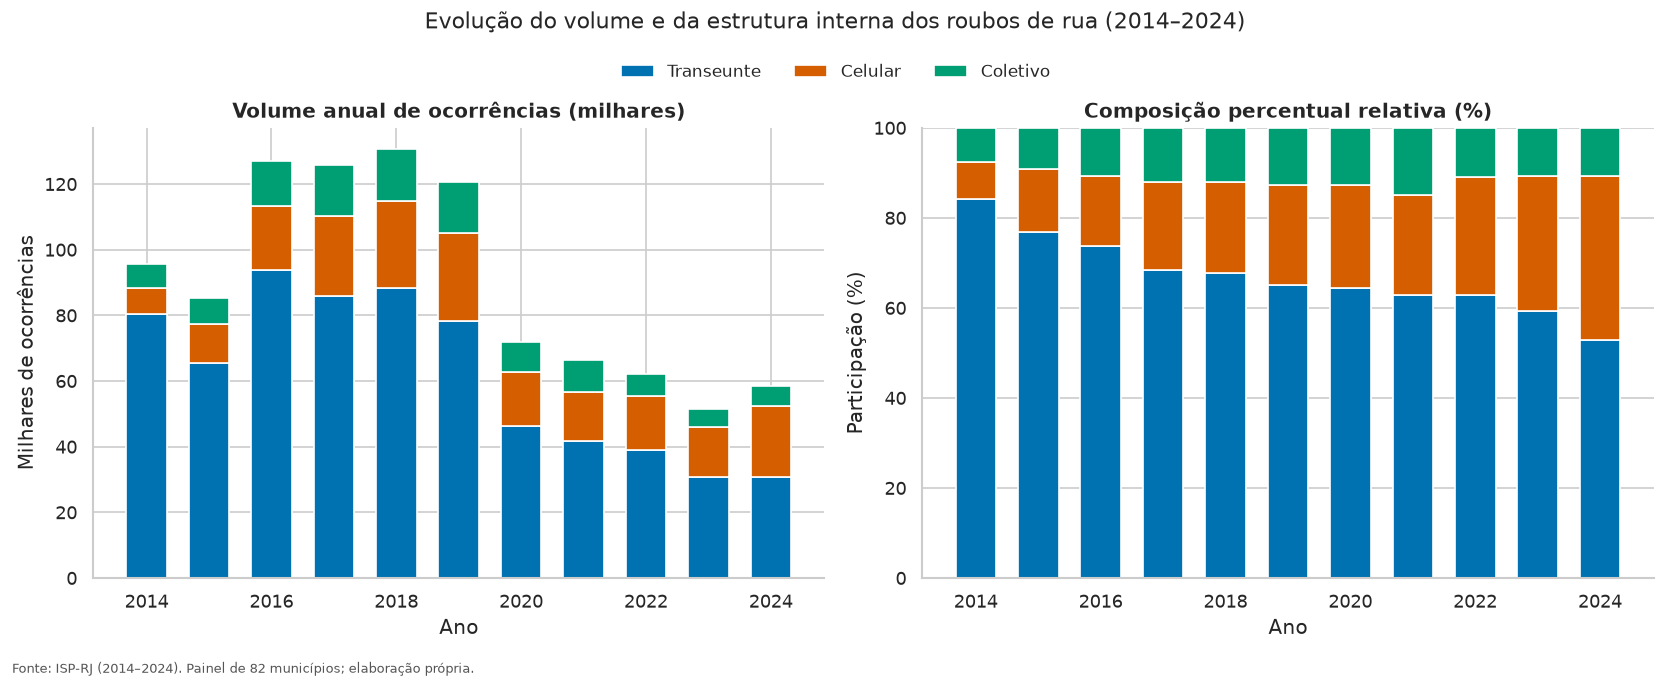

**O que o gráfico mostra.** Nos 82 municípios, os roubos de celular subiram de 7.758 em 2014 para 21.416 em 2024 (+176,1%), chegando a 26.779 registros em 2019. Nesse mesmo período, roubo a transeunte caiu 61,6% (80.461 → 30.868) e roubo em coletivo caiu 14,8% (7.314 → 6.235).

Com o recuo dos demais tipos, a fatia dos celulares ficou cerca de 4,5 vezes maior, passando de 8,1% em 2014 para 22,2% em 2019 e 36,6% em 2024 (+28,5 p.p.). A participação cresceu em ritmo parecido antes e depois de 2019. Duas hipóteses ajudam a pensar nessa mudança, sem que os dados separem quanto vem de cada uma: o aumento de valor e portabilidade dos aparelhos descrito na teoria das atividades rotineiras (Cohen & Felson, 1979) e mudanças na tipificação dos registros entre celular e transeunte.

In [8]:
components = ['roubo_transeunte', 'roubo_celular', 'roubo_em_coletivo']
comp_labels = {'roubo_transeunte': 'Transeunte', 'roubo_celular': 'Celular', 'roubo_em_coletivo': 'Coletivo'}
comp_colors = {'roubo_transeunte': '#0072B2', 'roubo_celular': '#D55E00', 'roubo_em_coletivo': '#009E73'}

annual_counts = panel_counts.groupby('ano')[components].sum()
annual_counts_k = annual_counts / 1000
pct_comp = 100 * annual_counts.div(annual_counts.sum(axis=1), axis=0)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.2))

bottom_k = np.zeros(len(annual_counts_k))
for comp in components:
    vals = annual_counts_k[comp]
    ax1.bar(annual_counts_k.index, vals, bottom=bottom_k, label=comp_labels[comp], color=comp_colors[comp], width=0.65)
    bottom_k += vals
ax1.set(title='Volume anual de ocorrências (milhares)', xlabel='Ano', ylabel='Milhares de ocorrências')
ax1.yaxis.set_major_formatter(br_int_axis)

bottom_pct = np.zeros(len(pct_comp))
for comp in components:
    vals = pct_comp[comp]
    ax2.bar(pct_comp.index, vals, bottom=bottom_pct, label=comp_labels[comp], color=comp_colors[comp], width=0.65)
    bottom_pct += vals
ax2.set(title='Composição percentual relativa (%)', xlabel='Ano', ylabel='Participação (%)', ylim=(0, 100))
ax2.yaxis.set_major_formatter(br_int_axis)

handles, labels = ax1.get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 0.98), ncol=3, frameon=False, fontsize=10)
fig.suptitle('Evolução do volume e da estrutura interna dos roubos de rua (2014–2024)', fontsize=13, y=1.04)
add_source(fig)
fig.tight_layout()
save(fig, '07_decomposicao_rua.png')

c14, c24 = annual_counts.loc[2014], annual_counts.loc[2024]
var_comp = 100 * (c24 / c14 - 1)
pct_cel_14 = pct_comp.loc[2014, 'roubo_celular']
pct_cel_19 = pct_comp.loc[2019, 'roubo_celular']
pct_cel_24 = pct_comp.loc[2024, 'roubo_celular']
ratio_cel = pct_cel_24 / pct_cel_14
cel_pico_val = int(annual_counts['roubo_celular'].max())
cel_pico_ano = int(annual_counts['roubo_celular'].idxmax())

interpretation(
    f'Nos 82 municípios, os roubos de celular subiram de {fmt_int(c14["roubo_celular"])} em 2014 para {fmt_int(c24["roubo_celular"])} em 2024 '
    f'({fmt_sinal(var_comp["roubo_celular"], 1)}%), chegando a {fmt_int(cel_pico_val)} registros em {cel_pico_ano}. '
    f'Nesse mesmo período, roubo a transeunte caiu {fmt_br(abs(var_comp["roubo_transeunte"]), 1)}% '
    f'({fmt_int(c14["roubo_transeunte"])} → {fmt_int(c24["roubo_transeunte"])}) e roubo em coletivo caiu {fmt_br(abs(var_comp["roubo_em_coletivo"]), 1)}% '
    f'({fmt_int(c14["roubo_em_coletivo"])} → {fmt_int(c24["roubo_em_coletivo"])}).\n\n'
    f'Com o recuo dos demais tipos, a fatia dos celulares ficou cerca de {fmt_br(ratio_cel, 1)} vezes maior, passando de {fmt_br(pct_cel_14, 1)}% em 2014 '
    f'para {fmt_br(pct_cel_19, 1)}% em 2019 e {fmt_br(pct_cel_24, 1)}% em 2024 ({fmt_sinal(pct_cel_24 - pct_cel_14, 1)} p.p.). '
    f'A participação cresceu em ritmo parecido antes e depois de 2019. Duas hipóteses ajudam a pensar nessa mudança, sem que os dados separem quanto vem de cada uma: '
    f'o aumento de valor e portabilidade dos aparelhos descrito na teoria das atividades rotineiras (Cohen & Felson, 1979) e mudanças na tipificação dos registros entre celular e transeunte.'
)

## 9. Pergunta 6: há padrões sazonais mensais consistentes?

**Transformação:** divisão da taxa mensal pelo número de dias do mês, normalização pela média diária anual de cada município e ano (100 = média local daquele ano), teste de Friedman em blocos de anos por grupo regional com coeficiente $W$ de Kendall, e teste equivalente sobre contagens estaduais somadas.  
**Visualização:** perfil médio com faixa P10–P90 entre os anos (06), mapa de calor ano × mês com mesma escala de cores nas duas categorias (08) e comparação direta entre região metropolitana e Interior no mesmo recorte vertical definido pelos dados (09).

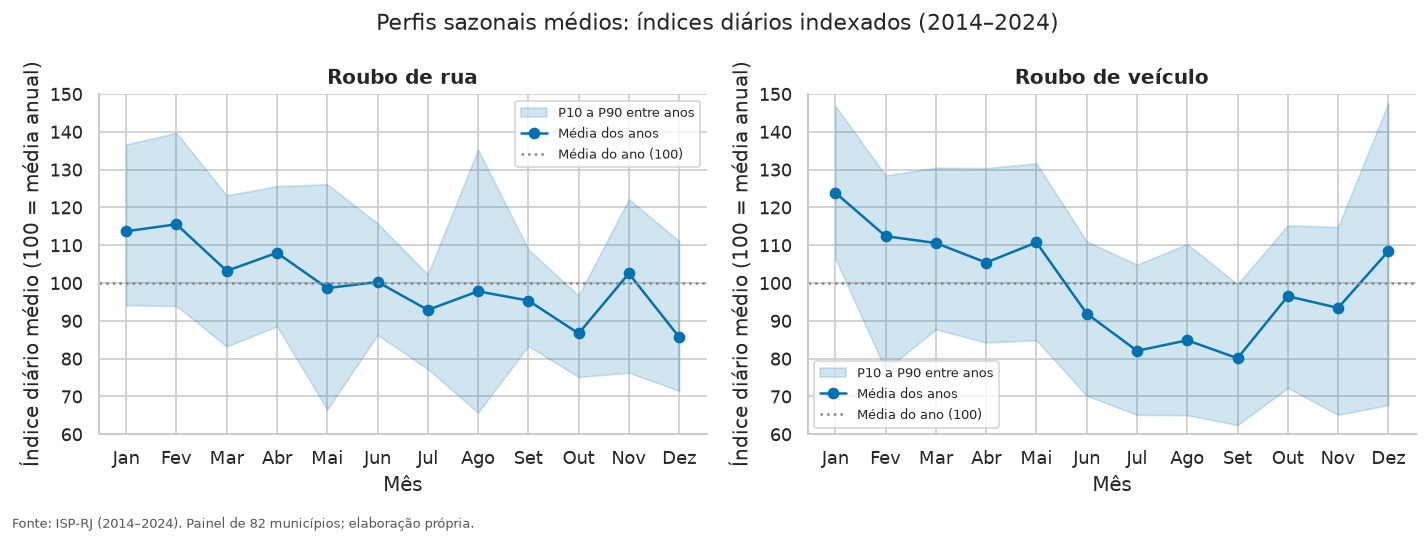

,Categoria,Grupo,Q (11 anos),p (11 anos),W Kendall,Q (sem 2020),p (sem 2020)
0,Roubo de rua,Painel 82 municípios,"21,78","0,0261","0,18","20,58","0,0379"
1,Roubo de rua,"Capital, Baixada e Grande Niterói","11,06","0,4386","0,09","10,71","0,4681"
2,Roubo de rua,Interior,"20,97","0,0337","0,17","19,05","0,0603"
3,Roubo de veículo,Painel 82 municípios,"35,74","0,0002","0,30","30,05","0,0016"
4,Roubo de veículo,"Capital, Baixada e Grande Niterói","27,32","0,0041","0,23","23,31","0,0160"
5,Roubo de veículo,Interior,"30,94","0,0011","0,26","26,63","0,0052"


,Categoria,Ponderação,Estatística Q,p-valor,W Kendall,Resultado
0,Roubo de rua,Contagens estaduais somadas (habitante típico),"16,17","0,1348","0,13","Não significante (p ≥ 0,05)"
1,Roubo de veículo,Contagens estaduais somadas (habitante típico),"23,24","0,0164","0,19","Significante (p < 0,05)"


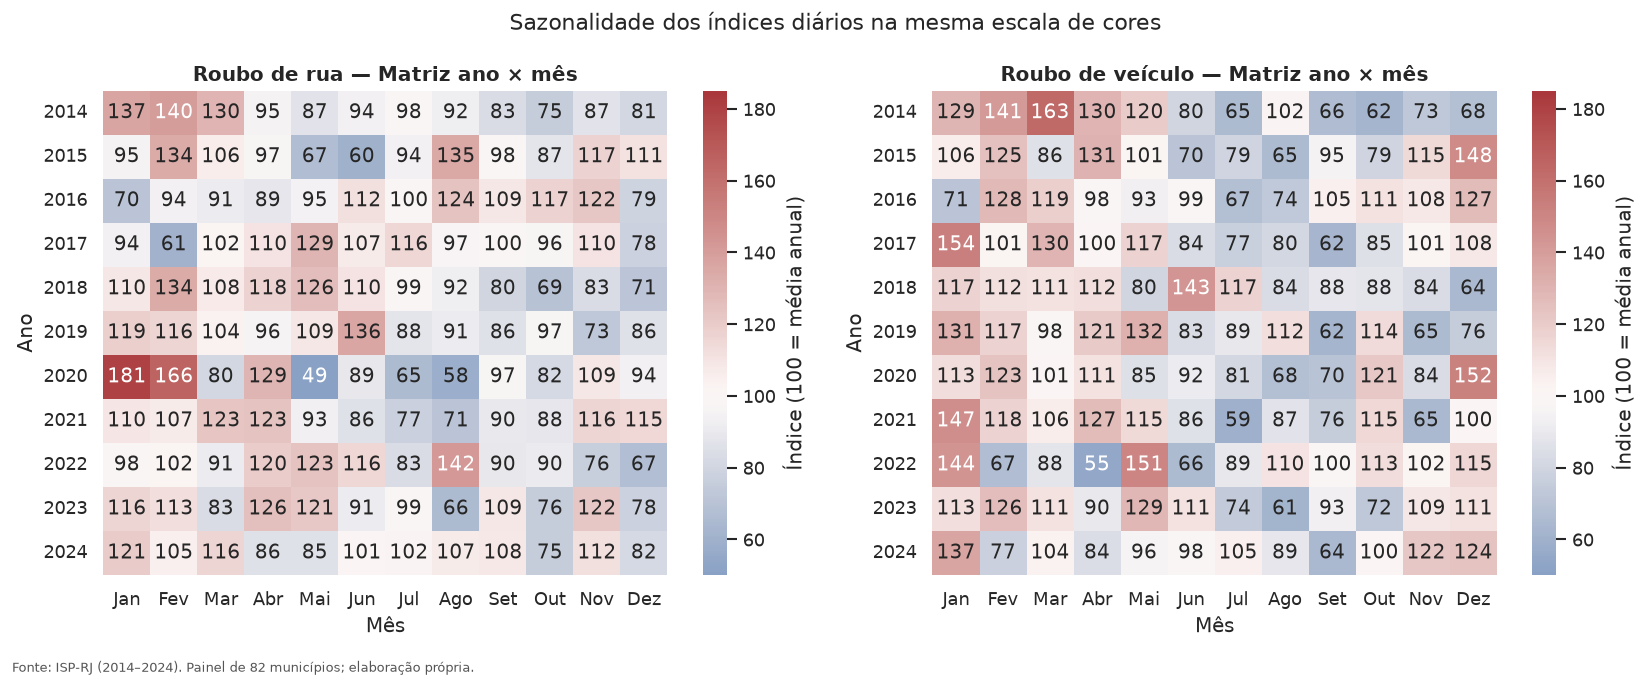

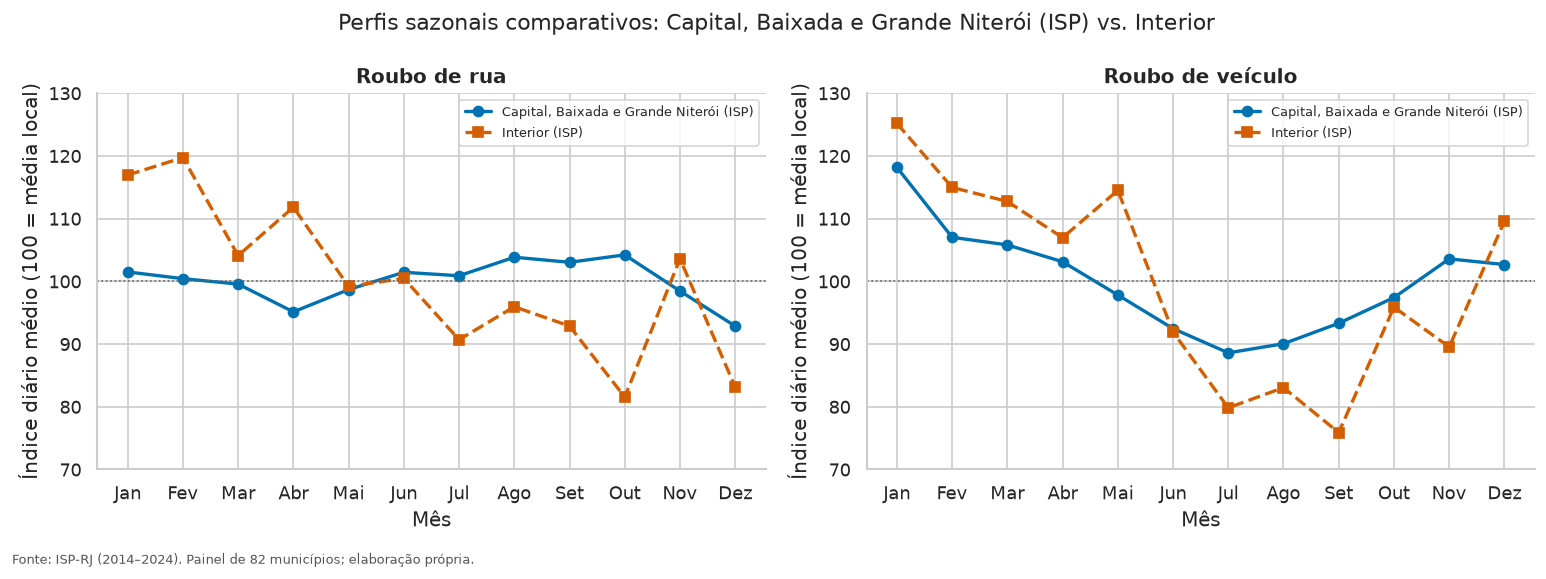

**O que o gráfico mostra.** Em roubo de veículos, o ciclo é regular e compartilhado: no teste de Friedman, tanto a região metropolitana (Q = 27,32, p = 0,0041, W = 0,23) quanto o Interior (Q = 30,94, p = 0,0011, W = 0,26) têm significância estatística. Janeiro traz as maiores médias (123,9 no painel e 118,2 na região metropolitana) e o inverno tem os menores valores (80,1 em setembro no painel; 88,6 em julho na região metropolitana).

Já em roubo de rua, na região metropolitana (Capital, Baixada e Grande Niterói), onde mora a maior parte da população do estado, não detectamos sazonalidade estatisticamente significativa (Q = 11,06, p = 0,4386, W = 0,09; sem 2020, p = 0,4681). O perfil metropolitano varia pouco ao longo do ano, entre 92,9 em dezembro e 104,2 em outubro (100,4 em fevereiro). O pico de fevereiro no painel (115,5) vem do Interior (119,7), grupo que reúne 65 dos 82 municípios e puxa a média não ponderada, embora ali o teste só passe sem correção (p = 0,0337) e deixe de passar sem 2020 (p = 0,0603). Turismo e Carnaval aparecem como hipóteses possíveis para esse comportamento do Interior, mas não foram testadas. Ano a ano os picos variaram bastante (agosto liderou 3 anos e fevereiro apenas 2).

Considerando os seis testes de Friedman realizados, com correção de Bonferroni (α = 0,05 / 6 ≈ 0,0083), os três recortes de veículos continuam significativos (p = 0,0002, 0,0041 e 0,0011), mas nenhum de roubo de rua passa do limiar (0,0261 no painel e 0,0337 no Interior). Em veículos, W de Kendall fica entre 0,23 e 0,30, indicando concordância baixa entre os anos. Quando avaliamos as contagens estaduais somadas (que dão mais peso aos municípios mais populosos), roubo de rua não atinge significância (p = 0,1348), enquanto roubo de veículo continua significativo ao nível de 5% (p = 0,0164).

In [9]:
analysis['dias'] = analysis['data'].dt.days_in_month
for metric in METRICS:
    analysis[f'taxa_diaria_{metric}'] = analysis[metric] / analysis['dias']
    m_ano = analysis.groupby(['fmun_cod', 'ano'])[f'taxa_diaria_{metric}'].transform('mean')
    analysis[f'idx_{metric}'] = 100 * analysis[f'taxa_diaria_{metric}'] / m_ano

matrices = {}
season_profiles = {}
for metric in METRICS:
    mat = analysis.groupby(['ano', 'mes'])[f'idx_{metric}'].mean().unstack(level=1)
    matrices[metric] = mat
    season_profiles[metric] = {
        'media': mat.mean(), 'desvio': mat.std(),
        'p10': mat.quantile(0.10), 'p90': mat.quantile(0.90)
    }

# 1. Perfis mensais com limites calculados a partir dos dados (sem cortar P10–P90)
MESES = ['Jan', 'Fev', 'Mar', 'Abr', 'Mai', 'Jun', 'Jul', 'Ago', 'Set', 'Out', 'Nov', 'Dez']
MESES_COMP = ['janeiro', 'fevereiro', 'março', 'abril', 'maio', 'junho',
              'julho', 'agosto', 'setembro', 'outubro', 'novembro', 'dezembro']

lo_06 = min(p['p10'].min() for p in season_profiles.values())
hi_06 = max(p['p90'].max() for p in season_profiles.values())
ylim_06 = (float(5 * np.floor(lo_06 / 5)), float(5 * np.ceil(hi_06 / 5)))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
for ax, metric in zip(axes, METRICS):
    prof = season_profiles[metric]
    ax.fill_between(range(1, 13), prof['p10'], prof['p90'], color='#0072B2', alpha=0.18, label='P10 a P90 entre anos')
    ax.plot(range(1, 13), prof['media'], marker='o', color='#0072B2', label='Média dos anos')
    ax.axhline(100, color='#888888', linestyle=':', label='Média do ano (100)')
    ax.set(title=LABEL[metric], xlabel='Mês', ylabel='Índice diário médio (100 = média anual)', ylim=ylim_06)
    ax.set_xticks(range(1, 13))
    ax.set_xticklabels(MESES)
    ax.yaxis.set_major_formatter(br_int_axis)
    ax.legend(fontsize=8)

fig.suptitle('Perfis sazonais médios: índices diários indexados (2014–2024)', fontsize=13)
add_source(fig)
fig.tight_layout()
save(fig, '06_perfil_mensal.png')

# 2. Friedman por grupos regionais e W de Kendall
analysis['macro_regiao'] = np.where(analysis.regiao == 'Interior', 'Interior', 'Capital, Baixada e Grande Niterói')
group_names = ['Painel 82 municípios', 'Capital, Baixada e Grande Niterói', 'Interior']

friedman_group_results = []
for metric in METRICS:
    for grp in group_names:
        sub = analysis if grp == 'Painel 82 municípios' else analysis[analysis.macro_regiao == grp]
        m_grp = sub.groupby(['ano', 'mes'])[f'idx_{metric}'].mean().unstack(level=1)
        q_g, p_g = stats.friedmanchisquare(*[m_grp[c] for c in m_grp.columns])
        w_g = q_g / (m_grp.shape[0] * (m_grp.shape[1] - 1))

        m_grp_s20 = m_grp.drop(index=2020)
        q_g20, p_g20 = stats.friedmanchisquare(*[m_grp_s20[c] for c in m_grp_s20.columns])

        friedman_group_results.append({
            'Categoria': LABEL[metric], 'Grupo': grp,
            'Q (11 anos)': fmt_br(q_g), 'p (11 anos)': f'{p_g:.4f}'.replace('.', ','), 'W Kendall': fmt_br(w_g),
            'Q (sem 2020)': fmt_br(q_g20), 'p (sem 2020)': f'{p_g20:.4f}'.replace('.', ',')
        })

df_fried_groups = pd.DataFrame(friedman_group_results)
display(df_fried_groups)

# 3. Ponderação: município típico vs. contagens somadas do estado
agg_counts = panel_counts.groupby(['ano', 'mes'])[['roubo_rua', 'roubo_veiculo']].sum().reset_index()
agg_counts['dias'] = pd.to_datetime(dict(year=agg_counts.ano, month=agg_counts.mes, day=1)).dt.days_in_month

pond_results = []
pond_p_vals = {}
for metric in METRICS:
    agg_counts[f'tx_{metric}'] = agg_counts[metric] / agg_counts['dias']
    m_ano = agg_counts.groupby('ano')[f'tx_{metric}'].transform('mean')
    agg_counts[f'idx_{metric}'] = 100 * agg_counts[f'tx_{metric}'] / m_ano
    m_agg = agg_counts.pivot(index='ano', columns='mes', values=f'idx_{metric}')
    q_agg, p_agg = stats.friedmanchisquare(*[m_agg[c] for c in m_agg.columns])
    w_agg = q_agg / (m_agg.shape[0] * (m_agg.shape[1] - 1))
    pond_p_vals[metric] = p_agg
    pond_results.append({
        'Categoria': LABEL[metric],
        'Ponderação': 'Contagens estaduais somadas (habitante típico)',
        'Estatística Q': fmt_br(q_agg), 'p-valor': f'{p_agg:.4f}'.replace('.', ','),
        'W Kendall': fmt_br(w_agg), 'Resultado': 'Significante (p < 0,05)' if p_agg < 0.05 else 'Não significante (p ≥ 0,05)'
    })

display(pd.DataFrame(pond_results))

# 4. Mapas de calor
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, metric in zip(axes, METRICS):
    mat = matrices[metric]
    sns.heatmap(mat, ax=ax, cmap='vlag', center=100, vmin=50, vmax=185, annot=True, fmt='.0f',
                cbar_kws={'label': 'Índice (100 = média anual)'},
                xticklabels=MESES)
    ax.set_yticklabels(mat.index, rotation=0)
    ax.set(title=f'{LABEL[metric]} — Matriz ano × mês', xlabel='Mês', ylabel='Ano')

fig.suptitle('Sazonalidade dos índices diários na mesma escala de cores', fontsize=13)
add_source(fig)
fig.tight_layout()
save(fig, '08_sazonalidade_heatmap.png')

# 5. Perfis comparativos: região metropolitana vs. Interior
macro_profiles = {
    metric: analysis.groupby(['macro_regiao', 'mes'])[f'idx_{metric}'].mean().unstack(level=0)
    for metric in METRICS
}
lo_09 = min(m.min().min() for m in macro_profiles.values()) - 5
hi_09 = max(m.max().max() for m in macro_profiles.values())
ylim_09 = (float(5 * np.floor(lo_09 / 5)), float(5 * np.ceil(hi_09 / 5)))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for ax, metric in zip(axes, METRICS):
    macro = macro_profiles[metric]
    ax.plot(macro.index, macro['Capital, Baixada e Grande Niterói'], marker='o', linewidth=2, color='#0072B2',
            label='Capital, Baixada e Grande Niterói (ISP)')
    ax.plot(macro.index, macro['Interior'], marker='s', linewidth=2, linestyle='--', color='#D55E00', label='Interior (ISP)')
    ax.axhline(100, color='#666666', linestyle=':', linewidth=1)
    ax.set(title=LABEL[metric], xlabel='Mês', ylabel='Índice diário médio (100 = média local)', ylim=ylim_09)
    ax.set_xticks(range(1, 13))
    ax.set_xticklabels(MESES)
    ax.yaxis.set_major_formatter(br_int_axis)
    ax.legend(fontsize=8)

fig.suptitle('Perfis sazonais comparativos: Capital, Baixada e Grande Niterói (ISP) vs. Interior', fontsize=13)
add_source(fig)
fig.tight_layout()
save(fig, '09_sazonalidade_regional.png')

# Variáveis para interpretação (sem f-string aninhada; README especifica Python 3.12 ou mais novo)
p_rua_agg = f"{pond_p_vals['roubo_rua']:.4f}".replace('.', ',')
p_veic_agg = f"{pond_p_vals['roubo_veiculo']:.4f}".replace('.', ',')

picos_rua_cont = matrices['roubo_rua'].idxmax(axis=1).value_counts().to_dict()
picos_fev_rua = picos_rua_cont.get(2, 0)
picos_ago_rua = picos_rua_cont.get(8, 0)

media_painel_veic = season_profiles['roubo_veiculo']['media']
pico_veic_val = media_painel_veic.max()
vale_veic_mes = MESES_COMP[int(media_painel_veic.idxmin()) - 1]
vale_veic_val = media_painel_veic.min()

media_painel_rua = season_profiles['roubo_rua']['media']
pico_rua_val = media_painel_rua.loc[2]

rua_metro_s = macro_profiles['roubo_rua']['Capital, Baixada e Grande Niterói']
rua_metro_min_val = rua_metro_s.min()
rua_metro_min_mes = MESES_COMP[int(rua_metro_s.idxmin()) - 1]
rua_metro_max_val = rua_metro_s.max()
rua_metro_max_mes = MESES_COMP[int(rua_metro_s.idxmax()) - 1]
rua_metro_fev = rua_metro_s.loc[2]
rua_int_fev = macro_profiles['roubo_rua']['Interior'].loc[2]

veic_metro_jan = macro_profiles['roubo_veiculo']['Capital, Baixada e Grande Niterói'].loc[1]
veic_metro_jul = macro_profiles['roubo_veiculo']['Capital, Baixada e Grande Niterói'].loc[7]

interpretation(
    f'Em roubo de veículos, o ciclo é regular e compartilhado: no teste de Friedman, tanto a região metropolitana '
    f'(Q = {df_fried_groups.loc[4, "Q (11 anos)"]}, p = {df_fried_groups.loc[4, "p (11 anos)"]}, W = {df_fried_groups.loc[4, "W Kendall"]}) '
    f'quanto o Interior (Q = {df_fried_groups.loc[5, "Q (11 anos)"]}, p = {df_fried_groups.loc[5, "p (11 anos)"]}, W = {df_fried_groups.loc[5, "W Kendall"]}) '
    f'têm significância estatística. Janeiro traz as maiores médias ({fmt_br(pico_veic_val, 1)} no painel e {fmt_br(veic_metro_jan, 1)} na região metropolitana) '
    f'e o inverno tem os menores valores ({fmt_br(vale_veic_val, 1)} em {vale_veic_mes} no painel; {fmt_br(veic_metro_jul, 1)} em julho na região metropolitana).\n\n'
    f'Já em roubo de rua, na região metropolitana (Capital, Baixada e Grande Niterói), onde mora a maior parte da população do estado, '
    f'não detectamos sazonalidade estatisticamente significativa (Q = {df_fried_groups.loc[1, "Q (11 anos)"]}, p = {df_fried_groups.loc[1, "p (11 anos)"]}, '
    f'W = {df_fried_groups.loc[1, "W Kendall"]}; sem 2020, p = {df_fried_groups.loc[1, "p (sem 2020)"]}). '
    f'O perfil metropolitano varia pouco ao longo do ano, entre {fmt_br(rua_metro_min_val, 1)} em {rua_metro_min_mes} e {fmt_br(rua_metro_max_val, 1)} '
    f'em {rua_metro_max_mes} ({fmt_br(rua_metro_fev, 1)} em fevereiro). O pico de fevereiro no painel ({fmt_br(pico_rua_val, 1)}) vem do Interior ({fmt_br(rua_int_fev, 1)}), '
    f'grupo que reúne 65 dos 82 municípios e puxa a média não ponderada, embora ali o teste só passe sem correção '
    f'(p = {df_fried_groups.loc[2, "p (11 anos)"]}) e deixe de passar sem 2020 (p = {df_fried_groups.loc[2, "p (sem 2020)"]}). '
    f'Turismo e Carnaval aparecem como hipóteses possíveis para esse comportamento do Interior, mas não foram testadas. '
    f'Ano a ano os picos variaram bastante (agosto liderou {picos_ago_rua} anos e fevereiro apenas {picos_fev_rua}).\n\n'
    f'Considerando os seis testes de Friedman realizados, com correção de Bonferroni (α = 0,05 / 6 ≈ 0,0083), os três recortes de veículos continuam significativos '
    f'(p = {df_fried_groups.loc[3, "p (11 anos)"]}, {df_fried_groups.loc[4, "p (11 anos)"]} e {df_fried_groups.loc[5, "p (11 anos)"]}), '
    f'mas nenhum de roubo de rua passa do limiar ({df_fried_groups.loc[0, "p (11 anos)"]} no painel e {df_fried_groups.loc[2, "p (11 anos)"]} no Interior). '
    f'Em veículos, W de Kendall fica entre {df_fried_groups.loc[4, "W Kendall"]} e {df_fried_groups.loc[3, "W Kendall"]}, indicando concordância baixa entre os anos. '
    f'Quando avaliamos as contagens estaduais somadas (que dão mais peso aos municípios mais populosos), '
    f'roubo de rua não atinge significância (p = {p_rua_agg}), enquanto roubo de veículo continua significativo ao nível de 5% (p = {p_veic_agg}).'
)

## 10. Sensibilidade: 82 vs. 92 municípios (2018–2024)

Para checar se a exclusão dos dez municípios zerados mudou a tendência da série, repetimos a comparação de 2018 a 2024 — período em que todos os 92 municípios têm registros — nos dois painéis.

In [10]:
p82 = df[~df.fmun_cod.isin(excluded) & df.ano.between(2018, 2024)].groupby(['fmun_cod', 'ano'])[METRICS].mean().reset_index()
m82 = p82.groupby('ano')[METRICS].mean()

p92 = df[df.ano.between(2018, 2024)].groupby(['fmun_cod', 'ano'])[METRICS].mean().reset_index()
m92 = p92.groupby('ano')[METRICS].mean()

sens_df = pd.DataFrame({
    'Painel': ['82 municípios (adotado)', '92 municípios (integral)', '82 municípios (adotado)', '92 municípios (integral)'],
    'Categoria': ['Roubo de rua', 'Roubo de rua', 'Roubo de veículo', 'Roubo de veículo'],
    'Média 2018': [fmt_br(m82.loc[2018, 'roubo_rua']), fmt_br(m92.loc[2018, 'roubo_rua']),
                   fmt_br(m82.loc[2018, 'roubo_veiculo']), fmt_br(m92.loc[2018, 'roubo_veiculo'])],
    'Média 2024': [fmt_br(m82.loc[2024, 'roubo_rua']), fmt_br(m92.loc[2024, 'roubo_rua']),
                   fmt_br(m82.loc[2024, 'roubo_veiculo']), fmt_br(m92.loc[2024, 'roubo_veiculo'])],
    'Variação 2018–2024': [
        f'{fmt_sinal(100*(m82.loc[2024, "roubo_rua"]/m82.loc[2018, "roubo_rua"]-1), 1)}%',
        f'{fmt_sinal(100*(m92.loc[2024, "roubo_rua"]/m92.loc[2018, "roubo_rua"]-1), 1)}%',
        f'{fmt_sinal(100*(m82.loc[2024, "roubo_veiculo"]/m82.loc[2018, "roubo_veiculo"]-1), 1)}%',
        f'{fmt_sinal(100*(m92.loc[2024, "roubo_veiculo"]/m92.loc[2018, "roubo_veiculo"]-1), 1)}%'
    ]
})
display(sens_df)

interpretation(
    f'Com os 92 municípios, as variações de 2018 a 2024 mudam menos de 0,2 ponto percentual '
    f'({sens_df.loc[0, "Variação 2018–2024"]} vs. {sens_df.loc[1, "Variação 2018–2024"]} em rua; '
    f'{sens_df.loc[2, "Variação 2018–2024"]} vs. {sens_df.loc[3, "Variação 2018–2024"]} em veículo), '
    f'então a exclusão dos 10 municípios não altera as conclusões.',
    prefix=''
)

,Painel,Categoria,Média 2018,Média 2024,Variação 2018–2024
0,82 municípios (adotado),Roubo de rua,"20,20","6,15","−69,6%"
1,92 municípios (integral),Roubo de rua,"18,14","5,49","−69,7%"
2,82 municípios (adotado),Roubo de veículo,"24,67","8,80","−64,3%"
3,92 municípios (integral),Roubo de veículo,"22,27","7,91","−64,5%"


Com os 92 municípios, as variações de 2018 a 2024 mudam menos de 0,2 ponto percentual (−69,6% vs. −69,7% em rua; −64,3% vs. −64,5% em veículo), então a exclusão dos 10 municípios não altera as conclusões.

## 11. Conclusão e resposta às hipóteses

A resposta à pergunta do título é não. A média dos municípios caiu muito, mas a queda foi bem diferente entre regiões, e os municípios ficaram mais desiguais entre si.

- **H1 — Confirmada.** A média municipal caiu 56,0% em roubo de rua e 57,7% em roubo de veículo de 2014 para 2024 (56,5% e 59,7% nos triênios). A queda não foi contínua: as taxas subiram até 2016 (rua) e 2017 (veículo), anos da crise fiscal do estado, e só depois começaram a cair. Não testamos se a crise explica esse pico.
- **H2 — Confirmada.** Em roubo de veículo, Grande Niterói caiu 76,5% e a Baixada 45,7%, enquanto a Capital terminou 2024 3,1% acima de 2014 por causa da alta de 2024 (nos triênios, ela caiu 22,1%). Nos triênios, Belford Roxo teve a maior alta (+5,41 pontos; e +17,45 no ponto a ponto), seguido de Rio Claro (+3,49) e outros nove municípios com menos de 1 ponto; as maiores quedas foram de outros municípios metropolitanos, como Nilópolis (−94,76) e São Gonçalo (−92,40). O CV e o Gini aumentaram nas duas categorias.
- **H3 — Confirmada para veículos e não confirmada para rua.** Veículo tem mais casos em janeiro e menos no inverno, com teste de Friedman significativo nas duas regiões mesmo após a correção de Bonferroni (W de 0,23 e 0,26). Rua não mostra sazonalidade na região metropolitana (p = 0,4386). O pico de fevereiro que aparece no painel vem do Interior, mas ali o teste só passa sem correção (p = 0,0337) e deixa de passar sem 2020 (p = 0,0603).

In [11]:
street = deltas.roubo_rua
vehicle = deltas.roubo_veiculo
summary_stats = pd.DataFrame({
    'Indicador': [
        'Variação da média municipal (2014 → 2024)',
        'Variação da média municipal por triênios (2014–16 → 2022–24)',
        'Municípios com redução no período (2014 → 2024)',
        'Municípios com redução por triênios',
        'Municípios com aumento por triênios',
        'Municípios com redução simultânea nos dois crimes (2014 → 2024)',
        'Variação da dispersão interdecil (P90–P10)',
        'Coeficiente de Variação no painel (2014 → 2024)',
        'Índice de Gini no painel (2014 → 2024)',
        'Participação de roubo de celular em rua (2014 → 2024)',
        'Friedman para sazonalidade — Painel geral',
        'Friedman — Região Metropolitana (ISP)'
    ],
    'Roubo de rua': [
        f'{fmt_sinal(changes.roubo_rua, 1)}%',
        f'{fmt_sinal(var_tri["roubo_rua"], 1)}%',
        f'{(street < 0).sum()} de 82',
        f'{q_tri_rua} de 82',
        f'{a_tri_rua} de 82',
        f'{q_ambas} de 82',
        f'{fmt_sinal(100*(gap_rua_24/gap_rua_14-1), 1)}%',
        f'{fmt_br(cv_series.loc[2014, "roubo_rua"])} → {fmt_br(cv_series.loc[2024, "roubo_rua"])} ({fmt_sinal(100*(cv_series.loc[2024, "roubo_rua"]/cv_series.loc[2014, "roubo_rua"]-1), 1)}%)',
        f'{fmt_br(g_rua_14)} → {fmt_br(g_rua_24)}',
        f'{fmt_br(pct_cel_14, 1)}% → {fmt_br(pct_cel_24, 1)}% ({fmt_sinal(pct_cel_24 - pct_cel_14, 1)} p.p.)',
        f'Q = {df_fried_groups.loc[0, "Q (11 anos)"]} (p = {df_fried_groups.loc[0, "p (11 anos)"]}; W = {df_fried_groups.loc[0, "W Kendall"]})',
        f'Q = {df_fried_groups.loc[1, "Q (11 anos)"]} (p = {df_fried_groups.loc[1, "p (11 anos)"]}; W = {df_fried_groups.loc[1, "W Kendall"]})'
    ],
    'Roubo de veículo': [
        f'{fmt_sinal(changes.roubo_veiculo, 1)}%',
        f'{fmt_sinal(var_tri["roubo_veiculo"], 1)}%',
        f'{(vehicle < 0).sum()} de 82',
        f'{q_tri_veic} de 82',
        f'{a_tri_veic} de 82',
        f'{q_ambas} de 82',
        f'{fmt_sinal(100*(gap_veic_24/gap_veic_14-1), 1)}%',
        f'{fmt_br(cv_series.loc[2014, "roubo_veiculo"])} → {fmt_br(cv_series.loc[2024, "roubo_veiculo"])} ({fmt_sinal(100*(cv_series.loc[2024, "roubo_veiculo"]/cv_series.loc[2014, "roubo_veiculo"]-1), 1)}%)',
        f'{fmt_br(g_veic_14)} → {fmt_br(g_veic_24)}',
        'Não se aplica',
        f'Q = {df_fried_groups.loc[3, "Q (11 anos)"]} (p = {df_fried_groups.loc[3, "p (11 anos)"]}; W = {df_fried_groups.loc[3, "W Kendall"]})',
        f'Q = {df_fried_groups.loc[4, "Q (11 anos)"]} (p = {df_fried_groups.loc[4, "p (11 anos)"]}; W = {df_fried_groups.loc[4, "W Kendall"]})'
    ]
})
display(summary_stats)

,Indicador,Roubo de rua,Roubo de veículo
0,Variação da média municipal (2014 → 2024),"−56,0%","−57,7%"
1,Variação da média municipal por triênios (2014...,"−56,5%","−59,7%"
2,Municípios com redução no período (2014 → 2024),65 de 82,65 de 82
3,Municípios com redução por triênios,78 de 82,70 de 82
4,Municípios com aumento por triênios,3 de 82,11 de 82
5,Municípios com redução simultânea nos dois cri...,56 de 82,56 de 82
6,Variação da dispersão interdecil (P90–P10),"−55,2%","−65,3%"
7,Coeficiente de Variação no painel (2014 → 2024),"1,65 → 1,86 (+12,8%)","1,61 → 2,27 (+41,1%)"
8,Índice de Gini no painel (2014 → 2024),"0,72 → 0,75","0,70 → 0,81"
9,Participação de roubo de celular em rua (2014 ...,"8,1% → 36,6% (+28,5 p.p.)",Não se aplica


## 12. Limitações e referências

O trabalho tem algumas limitações:

1. **Subnotificação e incentivos de registro:** Os dados representam ocorrências comunicadas à Polícia Civil, sujeitas à subnotificação e a diferenças no incentivo a registrar (como a necessidade de boletim para seguro de veículos).
2. **Médias sem ponderação:** Cada município pesa 1 nas médias do painel e das regiões; elas descrevem o município típico, não a taxa de vitimização do morador médio do estado.
3. **Denominadores e mudanças censitárias:** As taxas vêm prontas do ISP por 100 mil habitantes e por 100 mil veículos. As estimativas populacionais mudam quando sai um Censo (como o Censo de 2022), o que pode criar degraus nas taxas de rua; os arquivos usados também não trazem frota mensal nem fluxo de transeuntes por município.
4. **Grupos regionais desiguais em tamanho:** A Capital tem 1 município e Grande Niterói tem 3, contra 13 da Baixada Fluminense e 65 do Interior, então as médias dos dois primeiros grupos oscilam bem mais.
5. **Meses na fase 2 do ISP:** Como mostrado na auditoria da coluna `fase`, outubro a dezembro de 2024 (276 linhas) estão na fase 2 (consolidado sem errata), enquanto todo o período anterior está na fase 3 (consolidado com errata), então esses três últimos meses ainda podem receber revisão.
6. **Múltiplos testes na sazonalidade:** Foram feitos seis testes de Friedman nos recortes regionais. Mesmo aplicando a correção de Bonferroni (α = 0,0083), a conclusão não muda: roubo de veículo continua significativo nos três recortes e roubo de rua não atinge esse limiar em nenhum.
7. **Delimitação regional e escopo descritivo:** As quatro regiões administrativas do ISP diferem da Região Metropolitana definida pela Lei Complementar Estadual nº 184/2018 (22 municípios, incluindo Petrópolis, Itaboraí, Tanguá, Rio Bonito e Cachoeiras de Macacu, que na base do ISP aparecem no Interior). A análise é descritiva e não avalia efeito causal de políticas públicas.

### Referências

- **ISP-RJ — Base de taxas mensais por município (`BaseMunicipioTaxaMes.csv` / `taxas_municipais.csv`):** Instituto de Segurança Pública do Rio de Janeiro. Acesso em 30/09/2026. Disponível em: <https://www.ispdados.rj.gov.br/Arquivos/BaseMunicipioTaxaMes.csv>.
- **ISP-RJ — Base de contagens mensais por município (`BaseMunicipioMensal.csv` / `contagens_municipais.csv`):** Instituto de Segurança Pública do Rio de Janeiro. Acesso em 07/10/2026. Disponível em: <https://www.ispdados.rj.gov.br/Arquivos/BaseMunicipioMensal.csv>.
- **ISP-RJ — Dicionário de variáveis (`DicionarioDeVariaveisBaseMunicípioTaxaMês.xlsx` / `dicionario_taxas.xlsx`):** Instituto de Segurança Pública do Rio de Janeiro. Acesso em 07/10/2026. Disponível em: <https://www.ispdados.rj.gov.br/Arquivos/DicionarioDeVariaveisBaseMunic%C3%ADpioTaxaM%C3%AAs.xlsx>.
- **ISP-RJ — Nota metodológica:** Estatísticas oficiais de segurança pública do Estado do Rio de Janeiro. Acesso em 23/11/2026. Disponível em: <https://www.ispdados.rj.gov.br/metodDivulDados.html>.
- **TBRUGZ — `geodata-br` (`geojs-33-mun.json`):** Malha municipal do Estado do Rio de Janeiro em GeoJSON. Acesso em 18/11/2026. Disponível em: <https://raw.githubusercontent.com/tbrugz/geodata-br/master/geojson/geojs-33-mun.json>.
- **COHEN, L. E.; FELSON, M.** Social change and crime rate trends: A routine activity approach. *American Sociological Review*, v. 44, n. 4, p. 588–608, 1979.
- **RIO DE JANEIRO (Estado).** Lei Complementar nº 184, de 27 de dezembro de 2018. Dispõe sobre a Região Metropolitana do Rio de Janeiro. Assembleia Legislativa do Estado do Rio de Janeiro (ALERJ).